# Lab 02 — Pre-trained networks với PyTorch

**Bài toán:** phân loại 10 lớp CIFAR-10 RGB bằng ResNet18 và DenseNet121 pre-trained ImageNet.

**Câu hỏi:** hai kiến trúc khác nhau thế nào; head-only và fine-tune block cuối cho kết quả/chi phí ra sao; LR và batch size ảnh hưởng thế nào?

| Bước | Giai đoạn | Nội dung | Module | Bằng chứng |
|---|---|---|---|---|
| 1 | Setup | Runtime, MODE, cấu hình | src.experiment | environment/config |
| 2 | Dữ liệu | Split stratified, RGB, preprocessing theo weights | src.data | indices, data_summary |
| 3 | Kiến trúc | Xem lớp và tham số, thay classifier | src.models | architecture, parameters |
| 4 | Huấn luyện | Cache features, tìm LR/batch, fine-tune block cuối | src.experiment | search, selection, checkpoints |
| 5 | TensorBoard | Loss, accuracy, LR, ảnh và cấu hình | SummaryWriter | event files |
| 6 | So sánh | Learning curves, validation và test metrics | src.reporting | CSV, figures |
| 7 | Phân tích lỗi | Confusion matrix và mẫu đúng/sai | src.reporting | probabilities, report |
| 8 | Save/load | Tải vào instance mới, so xác suất | src.experiment | roundtrip.json |
| 9 | Kết luận | Phạm vi thật, giới hạn và tái lập | src.reporting | report_vi.md, manifest |

`MODE='view'` đọc run đã chọn. `MODE='train'` tạo run mới ở bước 4; bước này chạy trọn suite và giữ artifact ở từng giai đoạn. Profile cpu_full dùng toàn bộ dữ liệu, đầu vào 64×64 và ngân sách epoch CPU. Profile full dùng 224×224 cho GPU; không suy diễn kết quả của profile chưa chạy.


## 1. Setup

In [1]:
from pathlib import Path
import os, sys, json, inspect
import pandas as pd
from IPython.display import display, Markdown, Image

MODE = 'view'  # 'train' để chạy mới
PROFILE = 'cpu_full'  # toàn bộ 45000/5000/10000, ảnh 64x64; 'full' dùng 224x224
if MODE not in {'view', 'train'}:
    raise ValueError('MODE phải là view hoặc train')
candidates = [Path(os.environ.get('LAB02_ROOT', '.')).resolve(), *Path.cwd().resolve().parents]
ROOT = next((p for p in candidates if (p / 'src' / 'experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Đặt LAB02_ROOT đến thư mục lab2 chứa src/.')
sys.path.insert(0, str(ROOT))
WORK = Path('/kaggle/working/lab2') if Path('/kaggle/working').exists() else ROOT
CONFIG = ROOT / 'config' / f'{PROFILE}.json'
cfg = json.loads(CONFIG.read_text(encoding='utf-8'))
print('Cấu hình mặc định cho lượt chạy mới; cấu hình run thực tế hiển thị ở bước 4:')
display(cfg)


Cấu hình mặc định cho lượt chạy mới; cấu hình run thực tế hiển thị ở bước 4:


{'dataset': 'CIFAR10',
 'seed': 42,
 'threads': 4,
 'train_limit': 0,
 'val_limit': 0,
 'test_limit': 0,
 'models': ['resnet18', 'densenet121'],
 'learning_rates': [0.001, 0.01],
 'batch_sizes': [32, 64],
 'head_epochs': 5,
 'finetune_epochs': 2,
 'finetune_backbone_lr': 1e-05,
 'finetune_head_lr': 0.0001,
 'weight_decay': 0.0001,
 'feature_batch_size': 64,
 'image_size': 64,
 'cache_frozen_prefix': True,
 'profile': 'cifar10_cpu_full64',
 'notes': 'All 45000/5000/10000 samples. CPU budget: 64x64 RGB, fixed transforms; 5 head + 2 fine-tune epochs.'}

## 2. Dữ liệu và tiền xử lý

Split train/val stratified 45.000/5.000 từ 50.000 ảnh train; test chính thức 10.000 giữ riêng. Lưu indices và kiểm tra không trùng train/validation. Notebook 01 trình bày EDA trên ảnh RGB gốc và bảng phân bố lớp.

Giữ RGB, normalize theo `IMAGENET1K_V1`. Profile CPU resize 64×64; profile GPU dùng đầy đủ transforms 224×224 của weights. Đây là hai điều kiện khác nhau. Không augmentation để giữ đầu vào cố định cho cache feature và fine-tune.


In [2]:
from src.data import image_transform
for name in cfg['models']:
    print(name, image_transform(name, cfg['image_size']))


resnet18 Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
densenet121 Compose(
    Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 3. Khám phá và điều chỉnh kiến trúc

ResNet18 thay `fc`; DenseNet121 thay `classifier`; cả hai có 10 logits. Head-only chỉ cập nhật lớp mới. Fine-tune mở `layer4` hoặc `denseblock4 + norm5`, giữ BatchNorm running statistics để tránh thay đổi ngầm các phần đóng băng.


In [3]:
from src.models import build_model, configure_trainable, parameter_counts
print(inspect.getsource(build_model))
print(inspect.getsource(configure_trainable))
for name in cfg['models']:
    demo = build_model(name, pretrained=False)  # khảo sát cấu trúc; train dùng pretrained=True
    for stage in ['head', 'finetune']:
        configure_trainable(demo, name, stage)
        print(name, stage, parameter_counts(demo))
    del demo


def build_model(name, pretrained=True):
    builder, weights = SPECS[name]
    model = builder(weights=weights if pretrained else None)
    if name == "resnet18":
        model.fc = nn.Linear(model.fc.in_features, 10)
    else:
        model.classifier = nn.Linear(model.classifier.in_features, 10)
    return model

def configure_trainable(model, name, stage):
    for p in model.parameters():
        p.requires_grad = False
    for p in classifier(model, name).parameters():
        p.requires_grad = True
    if stage == "finetune":
        blocks = [model.layer4] if name == "resnet18" else [
            model.features.denseblock4, model.features.norm5]
        for block in blocks:
            for p in block.parameters():
                p.requires_grad = True

resnet18 head {'total': 11181642, 'trainable': 5130}
resnet18 finetune {'total': 11181642, 'trainable': 8398858}


densenet121 head {'total': 6964106, 'trainable': 10250}
densenet121 finetune {'total': 6964106, 'trainable': 2170378}


## 4. Head search và fine-tune

Candidate dùng cùng khởi tạo classifier và seed. Grid LR×batch chỉ chọn bằng validation; backbone cache ở eval mode nên tương đương forward cố định. Fine-tune tiếp tục từ head được chọn và có ngân sách bổ sung; comparison chưa cô lập tác động mở lớp ở cùng tổng epoch.

Cell dưới chạy mới chỉ ở MODE=train. Khi view, registry chọn run rõ ràng thay vì lấy thư mục mới nhất. Có thể đặt `LAB02_RUN` để xem một run khác.


In [4]:
if MODE == 'train':
    from src.experiment import run_suite
    RUN = run_suite(CONFIG, WORK)
else:
    override = os.environ.get('LAB02_RUN')
    if override:
        RUN = Path(override)
    else:
        registry = WORK / 'outputs' / 'selected_run.json'
        if not registry.exists():
            raise FileNotFoundError('Chưa có run. Chạy scripts/run.py hoặc đặt MODE=train.')
        RUN = Path(json.loads(registry.read_text(encoding='utf-8'))['run'])
if not RUN.is_absolute():
    RUN = ROOT / RUN
status = json.loads((RUN / 'status.json').read_text(encoding='utf-8'))
assert status['status'] == 'completed', status
print('Run:', RUN)
display(json.loads((RUN / 'environment.json').read_text(encoding='utf-8')))
display(json.loads((RUN / 'data_summary.json').read_text(encoding='utf-8')))
run_cfg = json.loads((RUN / 'config.json').read_text(encoding='utf-8'))
assert run_cfg.get('dataset') == 'CIFAR10', 'Run cũ khác dữ liệu; chọn run CIFAR-10'
display(run_cfg)
if (RUN / 'resume_config.json').exists():
    print('Cấu hình tiếp tục tại ranh giới kiến trúc:')
    display(json.loads((RUN / 'resume_config.json').read_text(encoding='utf-8')))
for name in run_cfg['models']:
    print('\nArchitecture:', name)
    print((RUN / name / 'architecture.txt').read_text(encoding='utf-8'))
    display(pd.read_csv(RUN / name / 'parameters.csv').head(12))
    display(pd.read_csv(RUN / name / 'search_results.csv'))
    display(json.loads((RUN / name / 'selection.json').read_text(encoding='utf-8')))
    if (RUN / name / 'prefix_equivalence.json').exists():
        print('Kiểm chứng cache prefix đóng băng trên ảnh thật:')
        display(json.loads((RUN / name / 'prefix_equivalence.json').read_text(encoding='utf-8')))
from src.experiment import pass_epoch
print('Vòng lặp train/validation được gọi bởi fit:')
print(inspect.getsource(pass_epoch))
from src.models import CachedTail
print('Tối ưu thực thi tương đương khi prefix đóng băng, BN cố định và không augmentation:')
print(inspect.getsource(CachedTail))


Run: D:\DL\lab2\outputs\runs\20261024T075133Z_cifar10_cpu_full64_71863a0e


{'python': '3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]',
 'torch': '2.14.1+cpu',
 'torchvision': '0.29.1+cpu',
 'device': 'cpu',
 'platform': 'Windows-10-10.0.19041-SP0',
 'cpu_count': 8}

{'selected_counts': {'train': 45000, 'val': 5000, 'test': 10000},
 'dataset': 'CIFAR10',
 'image_size': 64,
 'full_counts': {'train': 45000, 'val': 5000, 'test': 10000},
 'split_origin': 'stratified official CIFAR10 training pool; independent official test',
 'test_usage': 'evaluation only after validation selection',
 'class_counts': 'balanced stratification; inspect indices for exact membership'}

{'dataset': 'CIFAR10',
 'seed': 42,
 'threads': 4,
 'train_limit': 0,
 'val_limit': 0,
 'test_limit': 0,
 'models': ['resnet18', 'densenet121'],
 'learning_rates': [0.001, 0.01],
 'batch_sizes': [32, 64],
 'head_epochs': 5,
 'finetune_epochs': 2,
 'finetune_backbone_lr': 1e-05,
 'finetune_head_lr': 0.0001,
 'weight_decay': 0.0001,
 'feature_batch_size': 64,
 'image_size': 64,
 'profile': 'cifar10_cpu_full64',
 'notes': 'All 45000/5000/10000 samples. CPU budget: 64x64 RGB, fixed transforms; 5 head + 2 fine-tune epochs.'}

Cấu hình tiếp tục tại ranh giới kiến trúc:


...

,trial,lr,batch_size,best_val_accuracy,train_seconds,best_epoch
0,0,0.001,32,0.7852,13.351470,2
1,1,0.001,64,0.7924,8.981949,5
2,2,0.010,32,0.7584,12.547563,5
3,3,0.010,64,0.7452,8.529736,2


{'criterion': 'max validation accuracy, earliest trial on tie',
 'head': {'trial': 1,
  'lr': 0.001,
  'batch_size': 64,
  'best_val_accuracy': 0.7924,
  'train_seconds': 8.981949299999542,
  'best_epoch': 5},
 'finetune_policy': 'last block + classifier, fixed config, best validation epoch'}

Kiểm chứng cache prefix đóng băng trên ảnh thật:


{'passed': True,
 'samples': 8,
 'max_logit_error': 0.0,
 'policy': 'Frozen deterministic prefix cached once; original full-model checkpoint schema'}

Vòng lặp train/validation được gọi bởi fit:
def pass_epoch(model, loader, device, optimizer=None, mode_fn=None):
    training = optimizer is not None
    if training:
        (mode_fn or (lambda m: m.train()))(model)
    else:
        model.eval()
    total_loss, correct, count = 0., 0, 0
    with torch.enable_grad() if training else torch.inference_mode():
        for batch_number, (inputs, labels, *_) in enumerate(loader):
            inputs, labels = inputs.to(device), labels.to(device)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(inputs)
            loss = nn.functional.cross_entropy(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            count += len(labels)
            if batch_number and batch_number % 250 == 0:
                print(f"  {'tra

## 5. TensorBoard

Mỗi candidate và lượt fine-tune ghi train/validation loss, accuracy, LR từng nhóm tham số và hparams. Ảnh đầu vào cùng kiến trúc nằm trong input_preview. Bật cell dưới để theo dõi giao diện tương tác; event files đã được tạo khi train.


TensorBoard event files: 23
Log directory: D:\DL\lab2\outputs\runs\20261024T075133Z_cifar10_cpu_full64_71863a0e


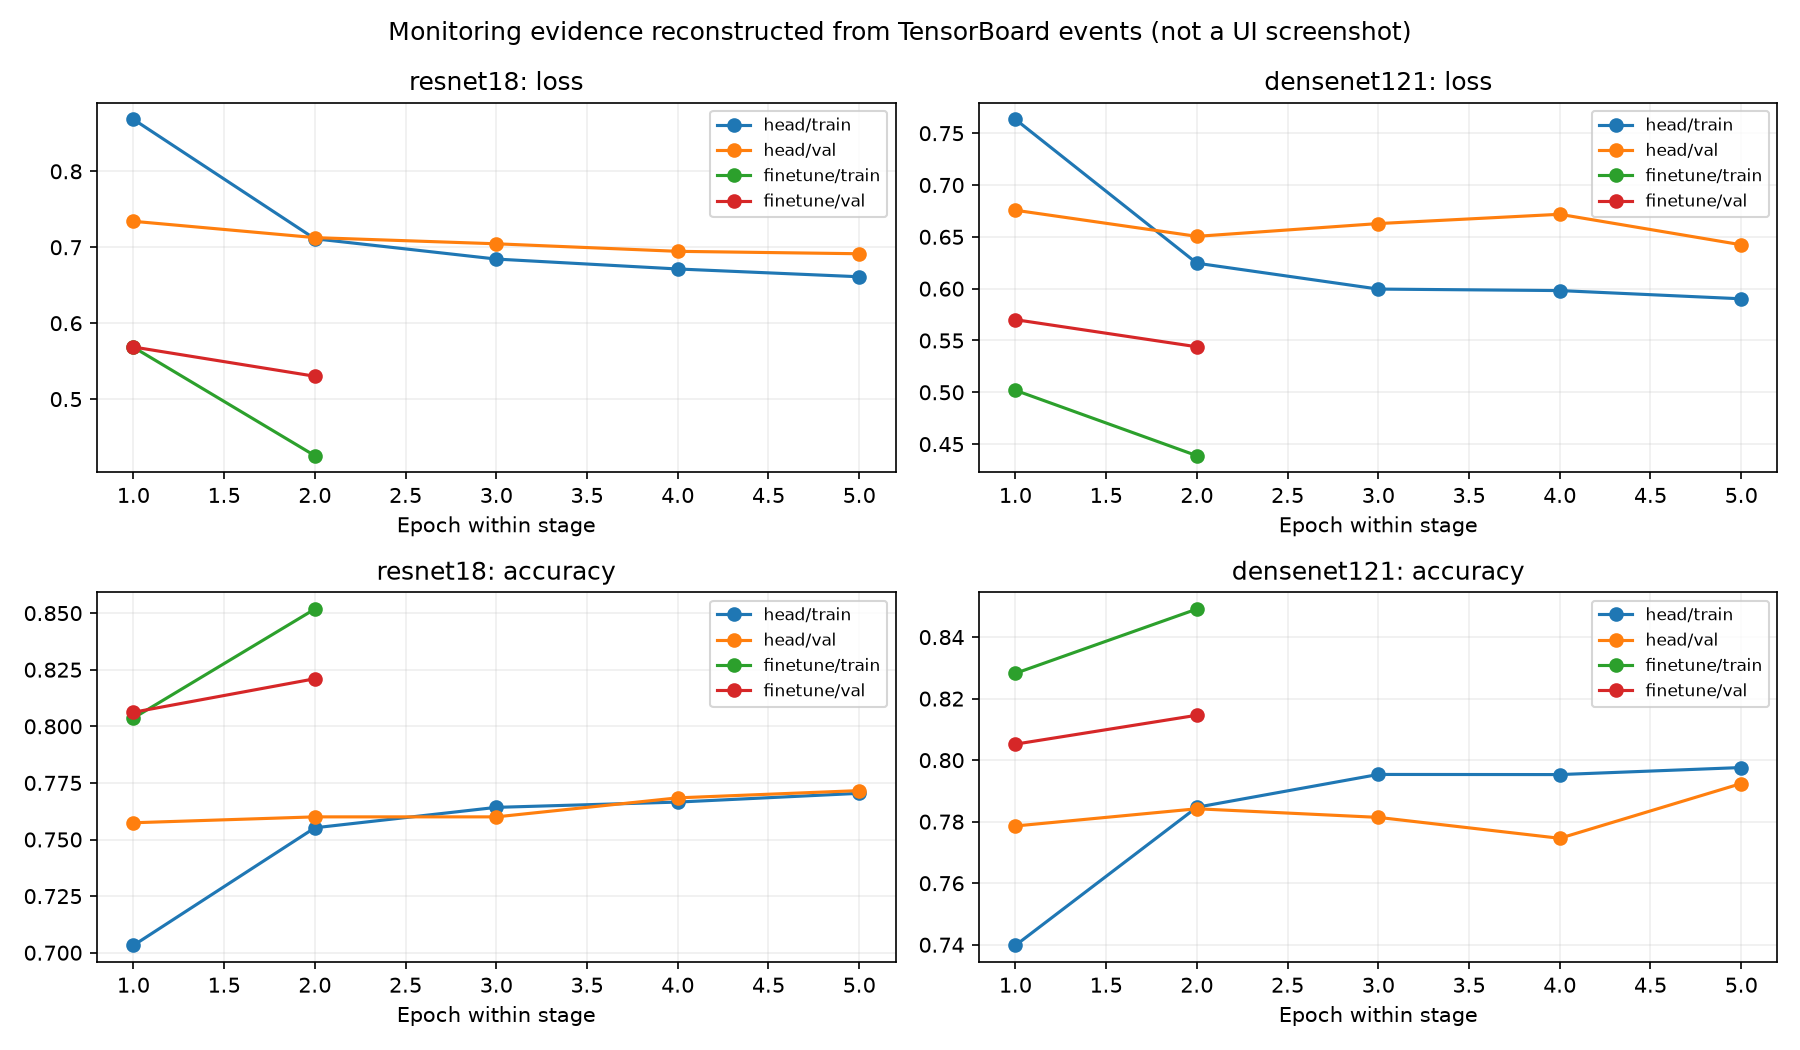

In [5]:
events = list(RUN.rglob('events.out.tfevents.*'))
print('TensorBoard event files:', len(events))
print('Log directory:', RUN)
if (RUN / 'tensorboard_evidence.png').exists():
    display(Image(filename=str(RUN / 'tensorboard_evidence.png')))
START_TENSORBOARD = False
if START_TENSORBOARD:
    get_ipython().run_line_magic('load_ext', 'tensorboard')
    get_ipython().run_line_magic('tensorboard', f'--logdir "{RUN}"')


## 6. Kết quả và chi phí

,model,stage,test_samples,accuracy,macro_f1,macro_precision,macro_recall,loss,best_val_accuracy,train_seconds,test_seconds,feature_extraction_train_val_seconds,total,trainable
0,resnet18,head,10000,0.7609,0.761075,0.763462,0.7609,0.706896,0.7716,8.888558,64.002694,281.856498,11181642,5130
1,resnet18,finetune,10000,0.8149,0.814634,0.815284,0.8149,0.547387,0.8210,1084.699019,62.763299,281.856498,11181642,8398858
2,densenet121,head,10000,0.7821,0.781146,0.786055,0.7821,0.660355,0.7924,8.981949,100.404374,478.102545,6964106,10250
3,densenet121,finetune,10000,0.8153,0.815109,0.815191,0.8153,0.547715,0.8146,219.661826,92.385364,478.102545,6964106,2170378


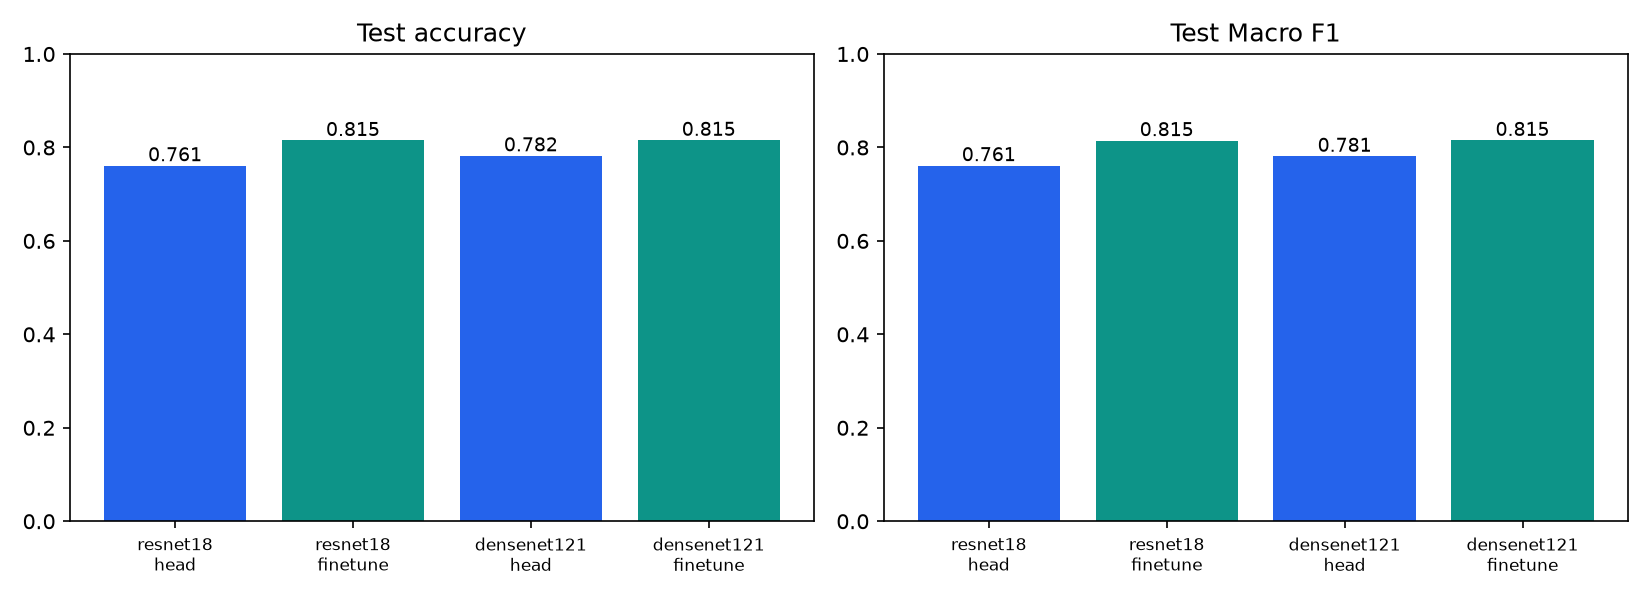

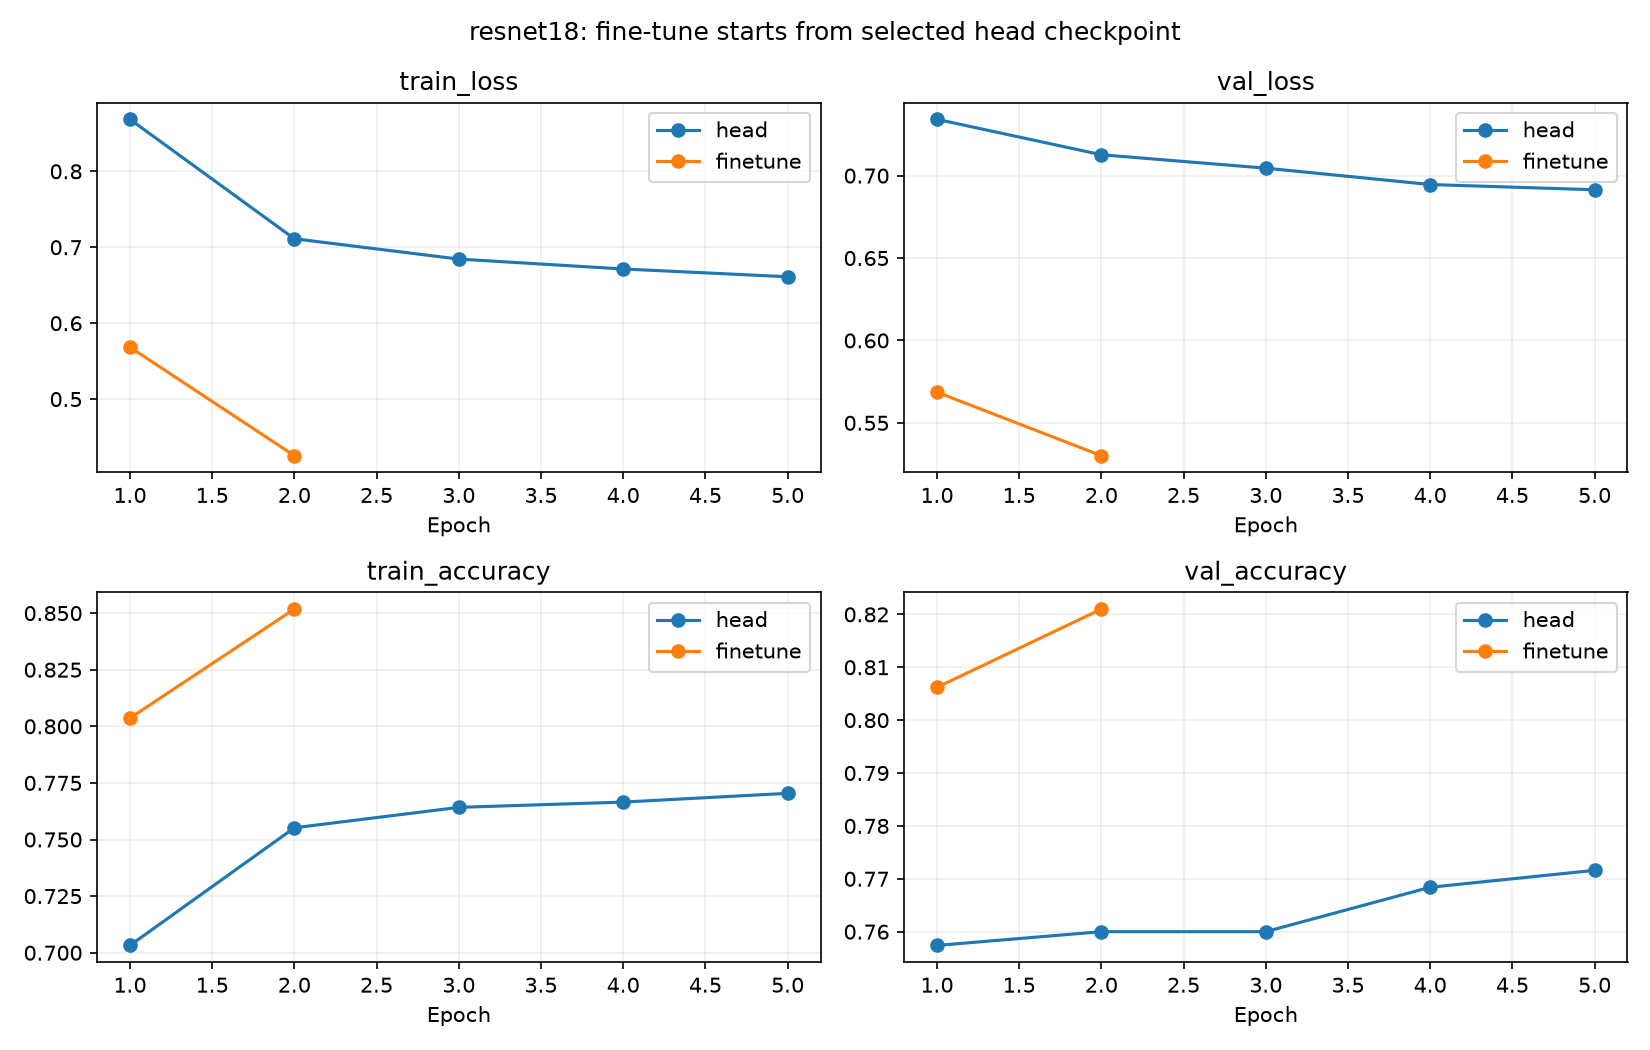

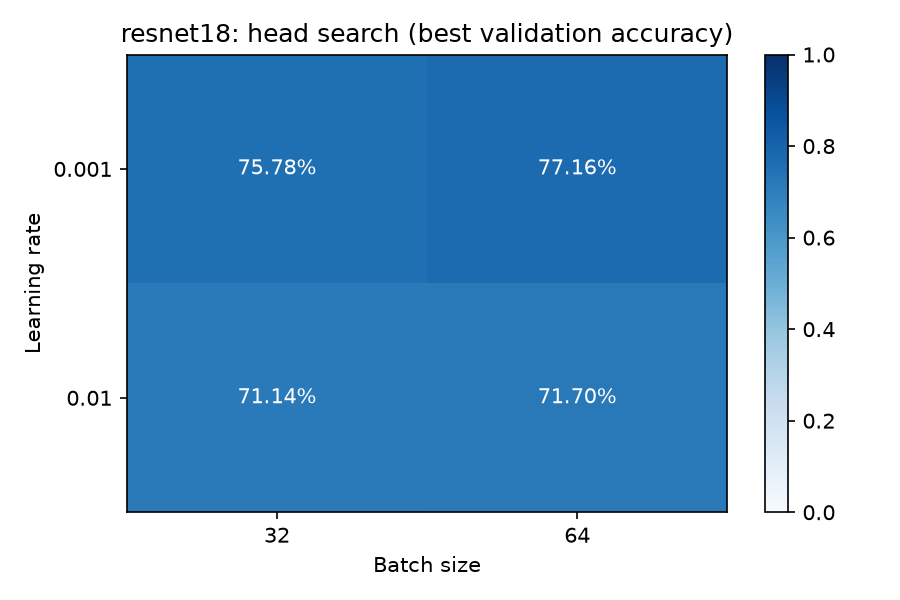

{'trial': 1,
 'lr': 0.001,
 'batch_size': 64,
 'best_val_accuracy': 0.7716,
 'train_seconds': 8.888557799999035,
 'best_epoch': 5,
 'feature_extraction_train_val_seconds': 281.8564978000013,
 'all_search_training_seconds': 47.59092899999996}

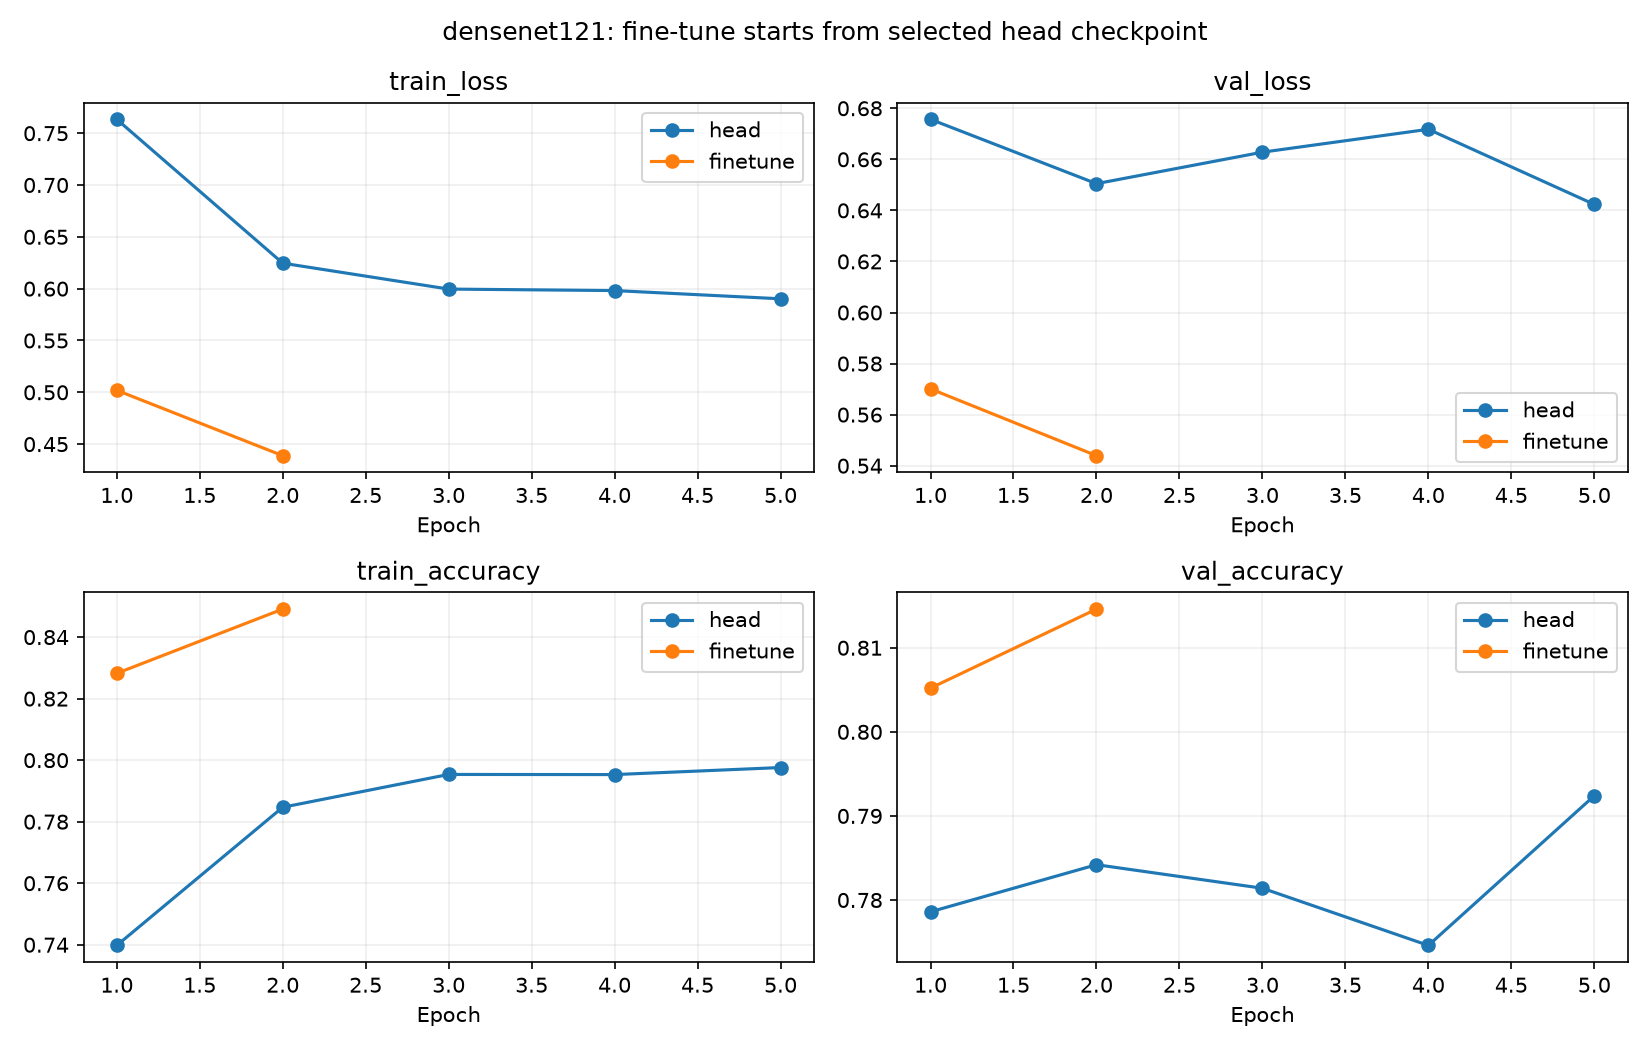

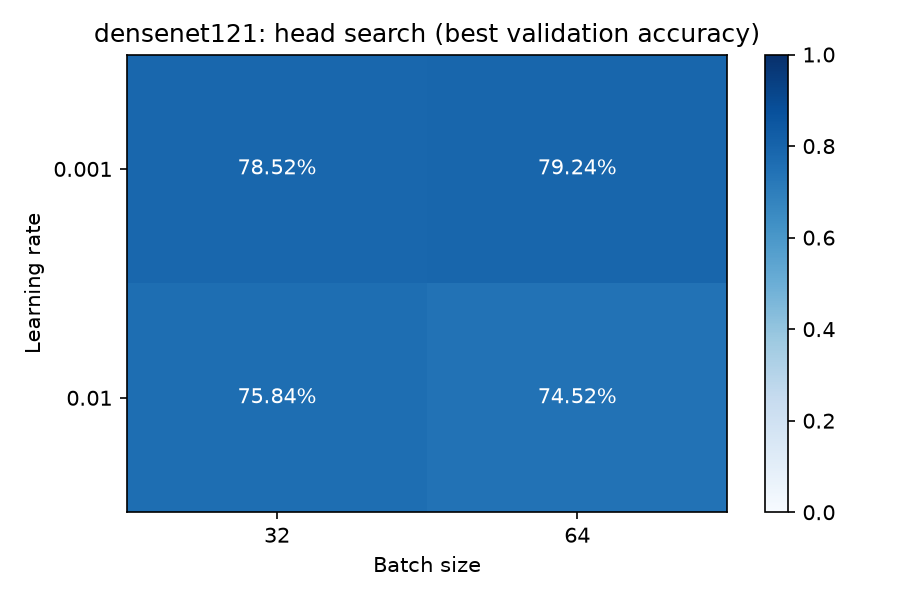

{'trial': 1,
 'lr': 0.001,
 'batch_size': 64,
 'best_val_accuracy': 0.7924,
 'train_seconds': 8.981949299999542,
 'best_epoch': 5,
 'feature_extraction_train_val_seconds': 478.10254480000185,
 'all_search_training_seconds': 43.4107189999977}

,model,stage,execution,feature_extraction_seconds,all_head_trials_fit_seconds,selected_stage_fit_seconds,pipeline_training_seconds,test_seconds,trainable_parameters
0,resnet18,head,pooled_feature_cache,281.856498,47.590929,8.888558,329.447427,64.002694,5130
1,resnet18,finetune,full_image_forward,281.856498,47.590929,1084.699019,1414.146445,62.763299,8398858
2,densenet121,head,pooled_feature_cache,478.102545,43.410719,8.981949,521.513264,100.404374,10250
3,densenet121,finetune,cached_frozen_prefix,478.102545,43.410719,219.661826,741.175090,92.385364,2170378


In [6]:
results = pd.read_csv(RUN / 'comparison.csv')
display(results)
display(Image(filename=str(RUN / 'comparison.png')))
for name in run_cfg['models']:
    display(Image(filename=str(RUN / name / 'learning_curves.png')))
    display(Image(filename=str(RUN / name / 'hyperparameter_search.png')))
    display(json.loads((RUN / name / 'head_selected' / 'training_summary.json').read_text(encoding='utf-8')))
if (RUN / 'cost_comparison.csv').exists():
    display(pd.read_csv(RUN / 'cost_comparison.csv'))


## 7. Confusion matrix và dự đoán

Mọi ô confusion matrix có count; màu là tỷ lệ theo lớp thật. Lưới ảnh gồm tối đa 8 đúng và 8 sai để khảo sát lỗi, không đại diện accuracy toàn test. Softmax confidence có thể cao khi dự đoán sai.


resnet18 head_selected


,precision,recall,f1-score,support
airplane,0.711304,0.8180,0.760930,1000.0000
automobile,0.814885,0.8540,0.833984,1000.0000
bird,0.728261,0.6700,0.697917,1000.0000
cat,0.633955,0.6460,0.639921,1000.0000
deer,0.671196,0.7410,0.704373,1000.0000
dog,0.773649,0.6870,0.727754,1000.0000
frog,0.811983,0.7860,0.798780,1000.0000
horse,0.790419,0.7920,0.791209,1000.0000
ship,0.856250,0.8220,0.838776,1000.0000
truck,0.842721,0.7930,0.817105,1000.0000


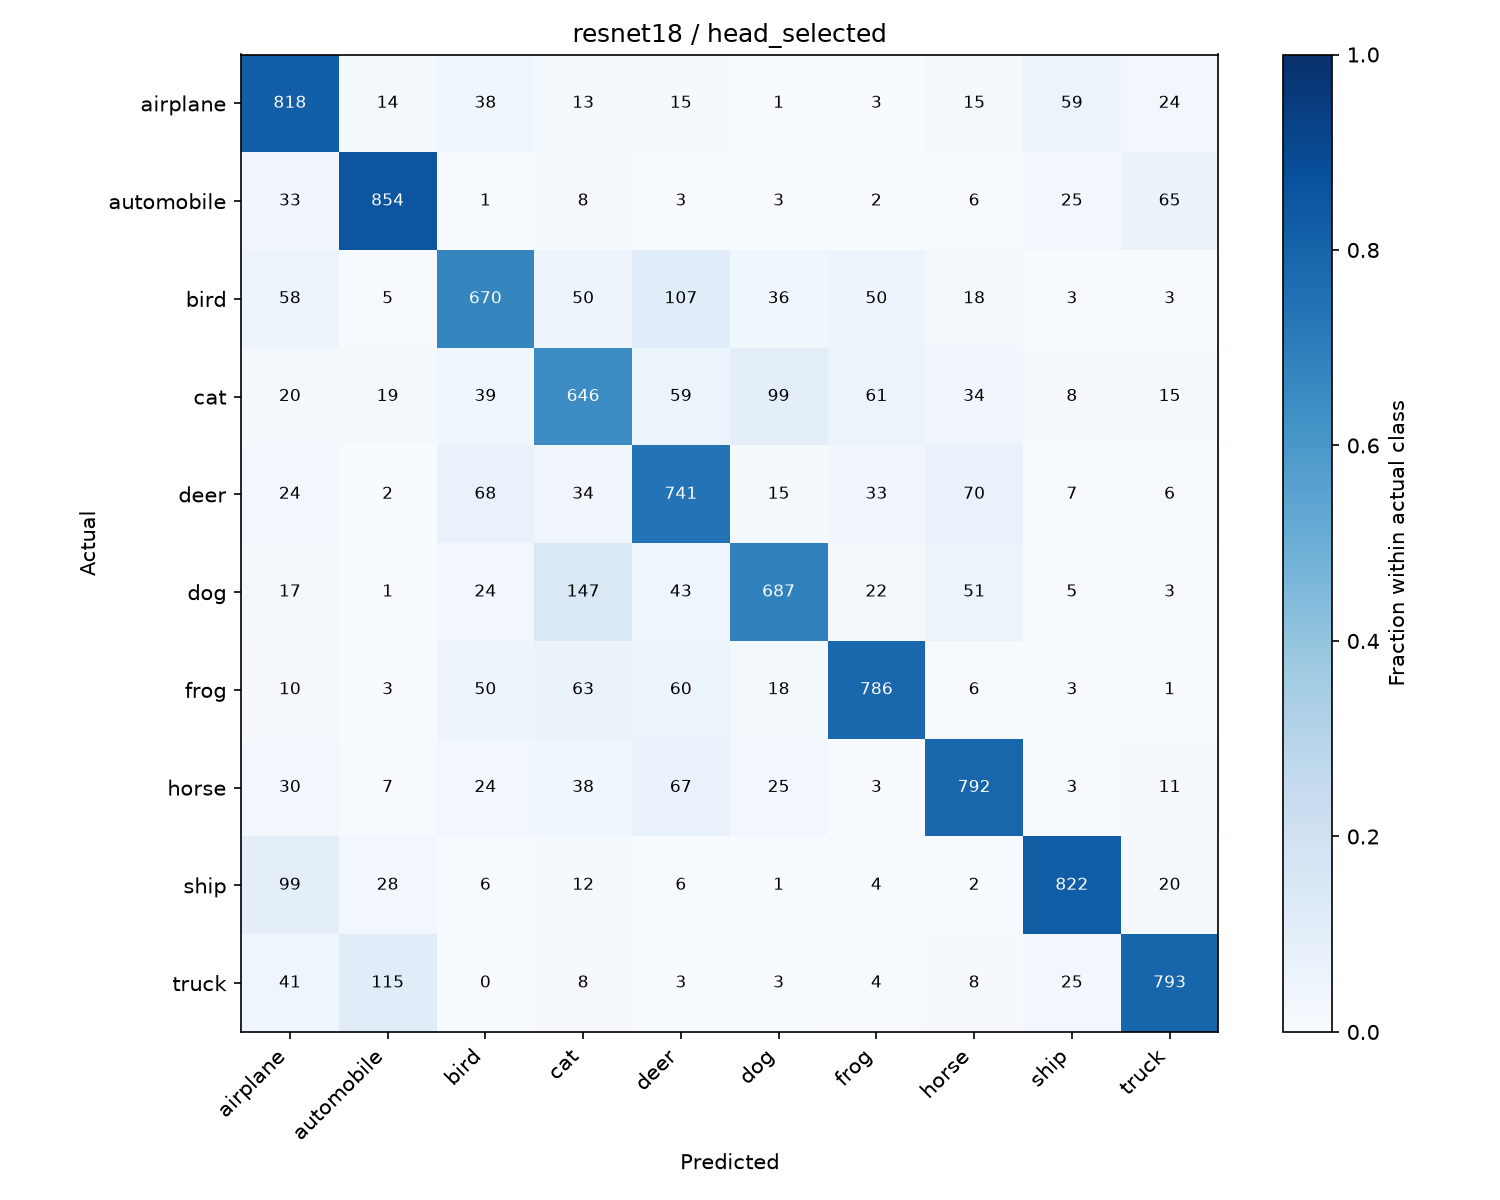

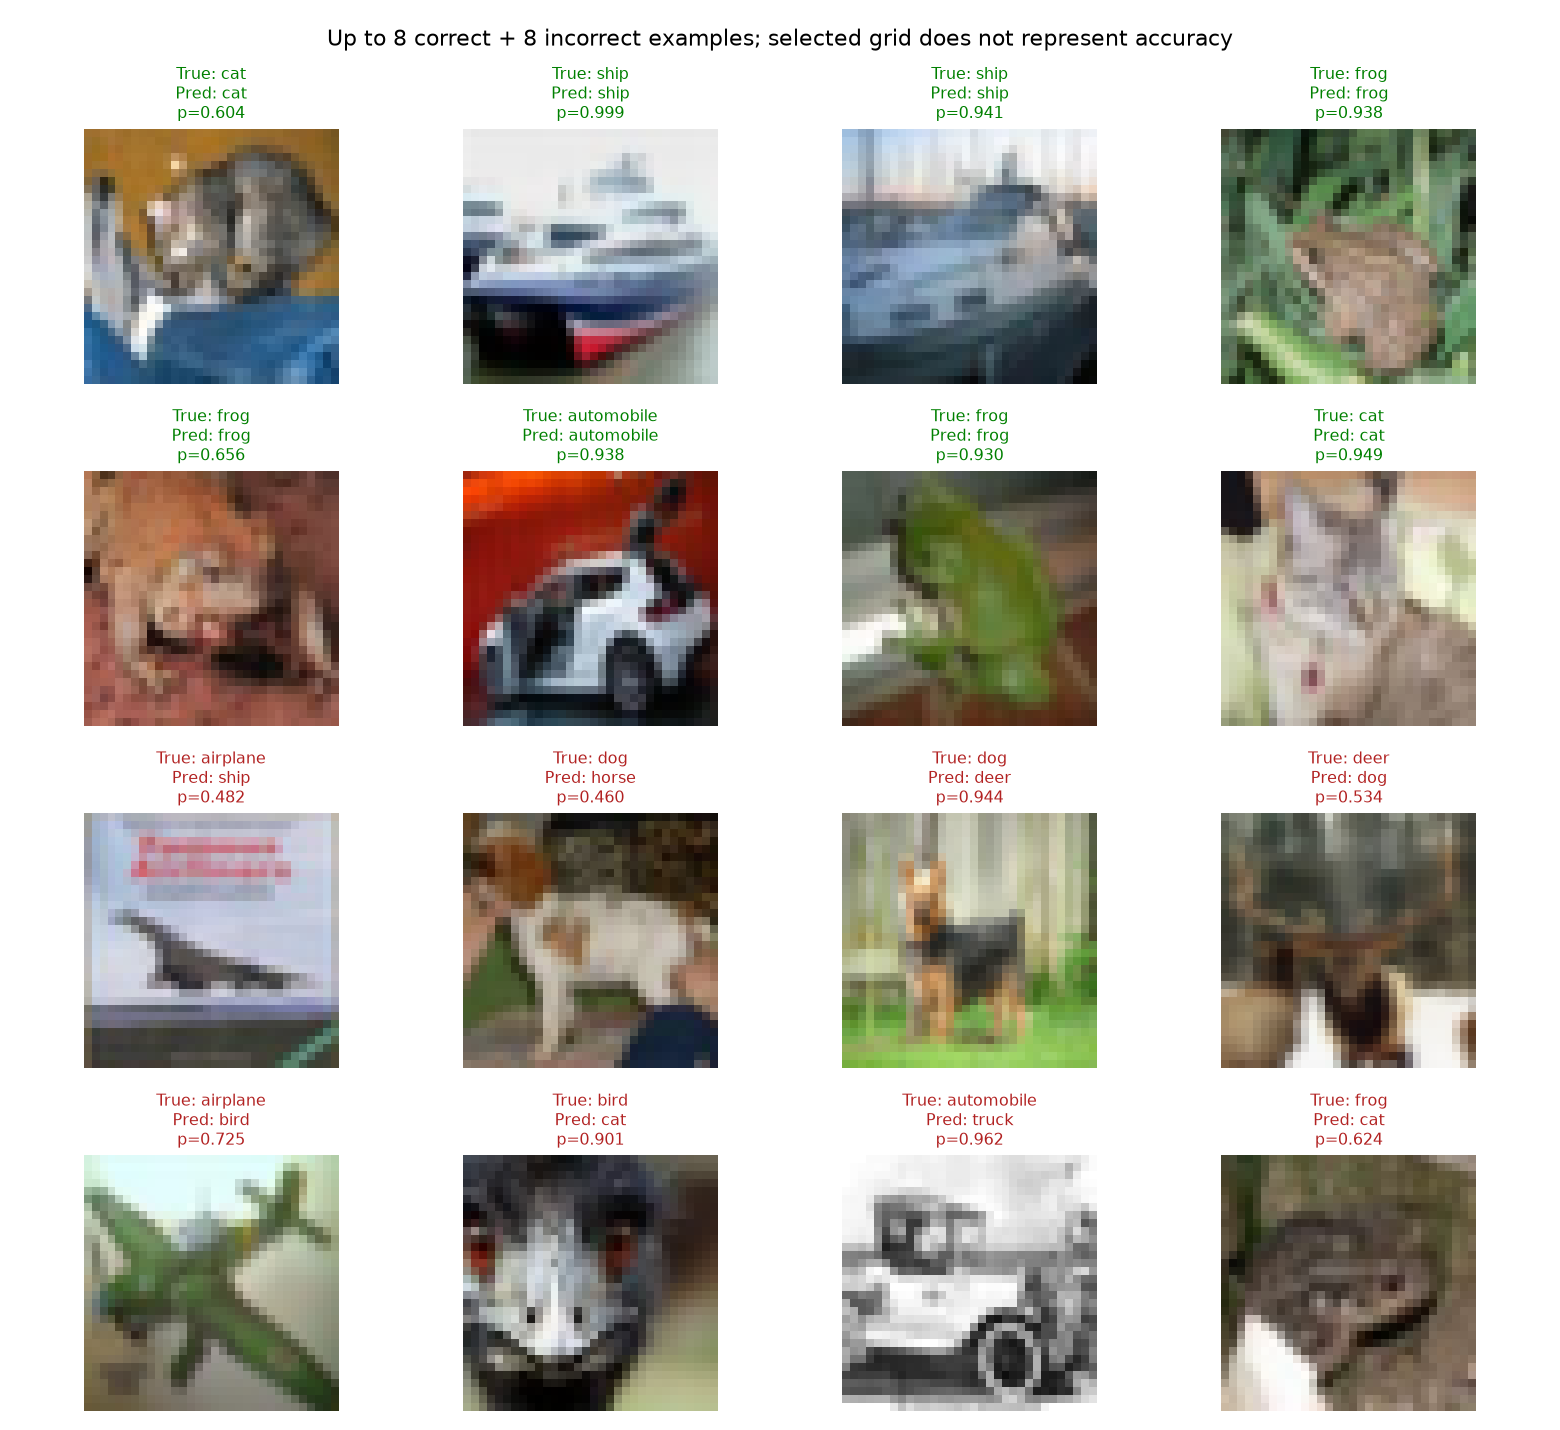

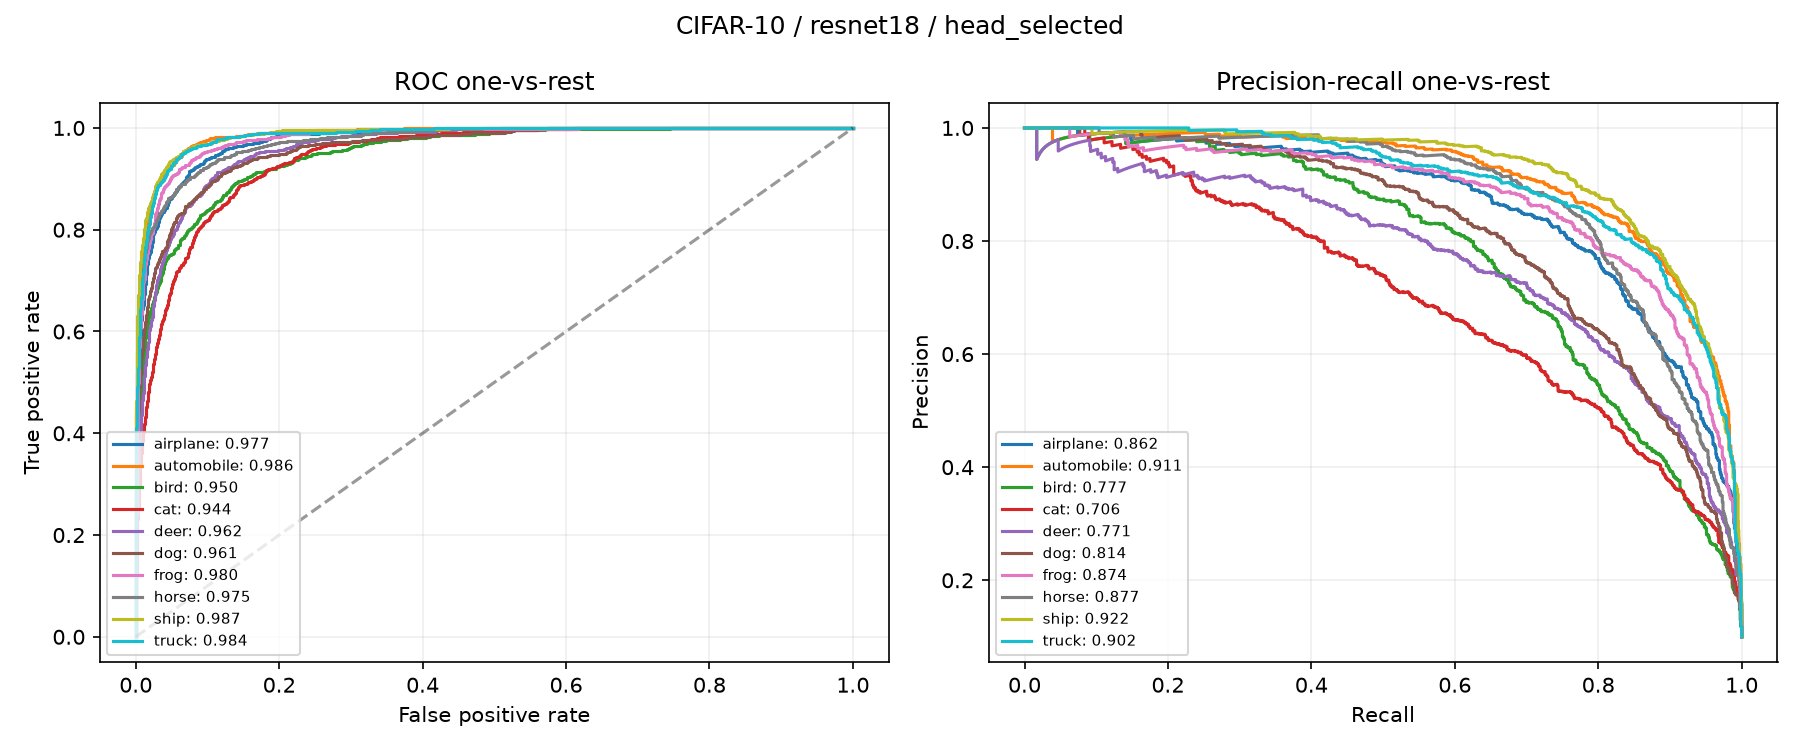

resnet18 finetune


,precision,recall,f1-score,support
airplane,0.799239,0.8400,0.819113,1000.0000
automobile,0.883316,0.8630,0.873040,1000.0000
bird,0.757812,0.7760,0.766798,1000.0000
cat,0.694831,0.6990,0.696909,1000.0000
deer,0.797706,0.7650,0.781011,1000.0000
dog,0.787781,0.7350,0.760476,1000.0000
frog,0.831901,0.8710,0.851001,1000.0000
horse,0.881537,0.8260,0.852865,1000.0000
ship,0.843083,0.9080,0.874338,1000.0000
truck,0.875632,0.8660,0.870789,1000.0000


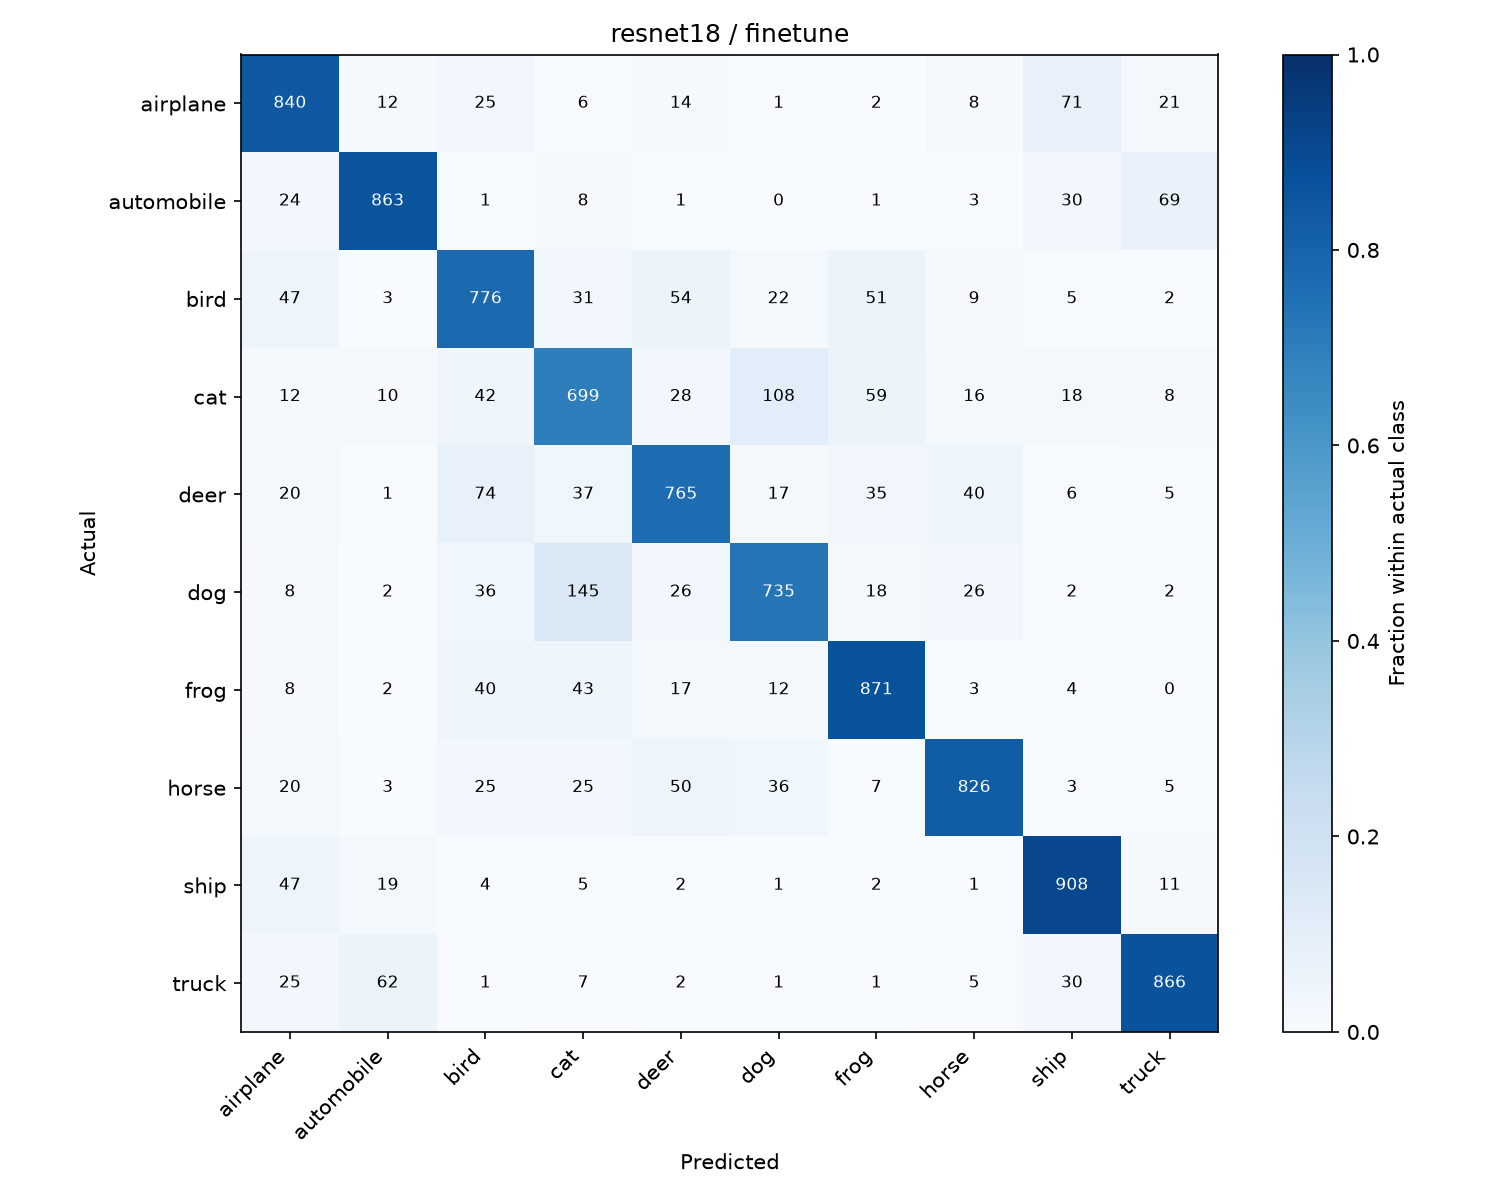

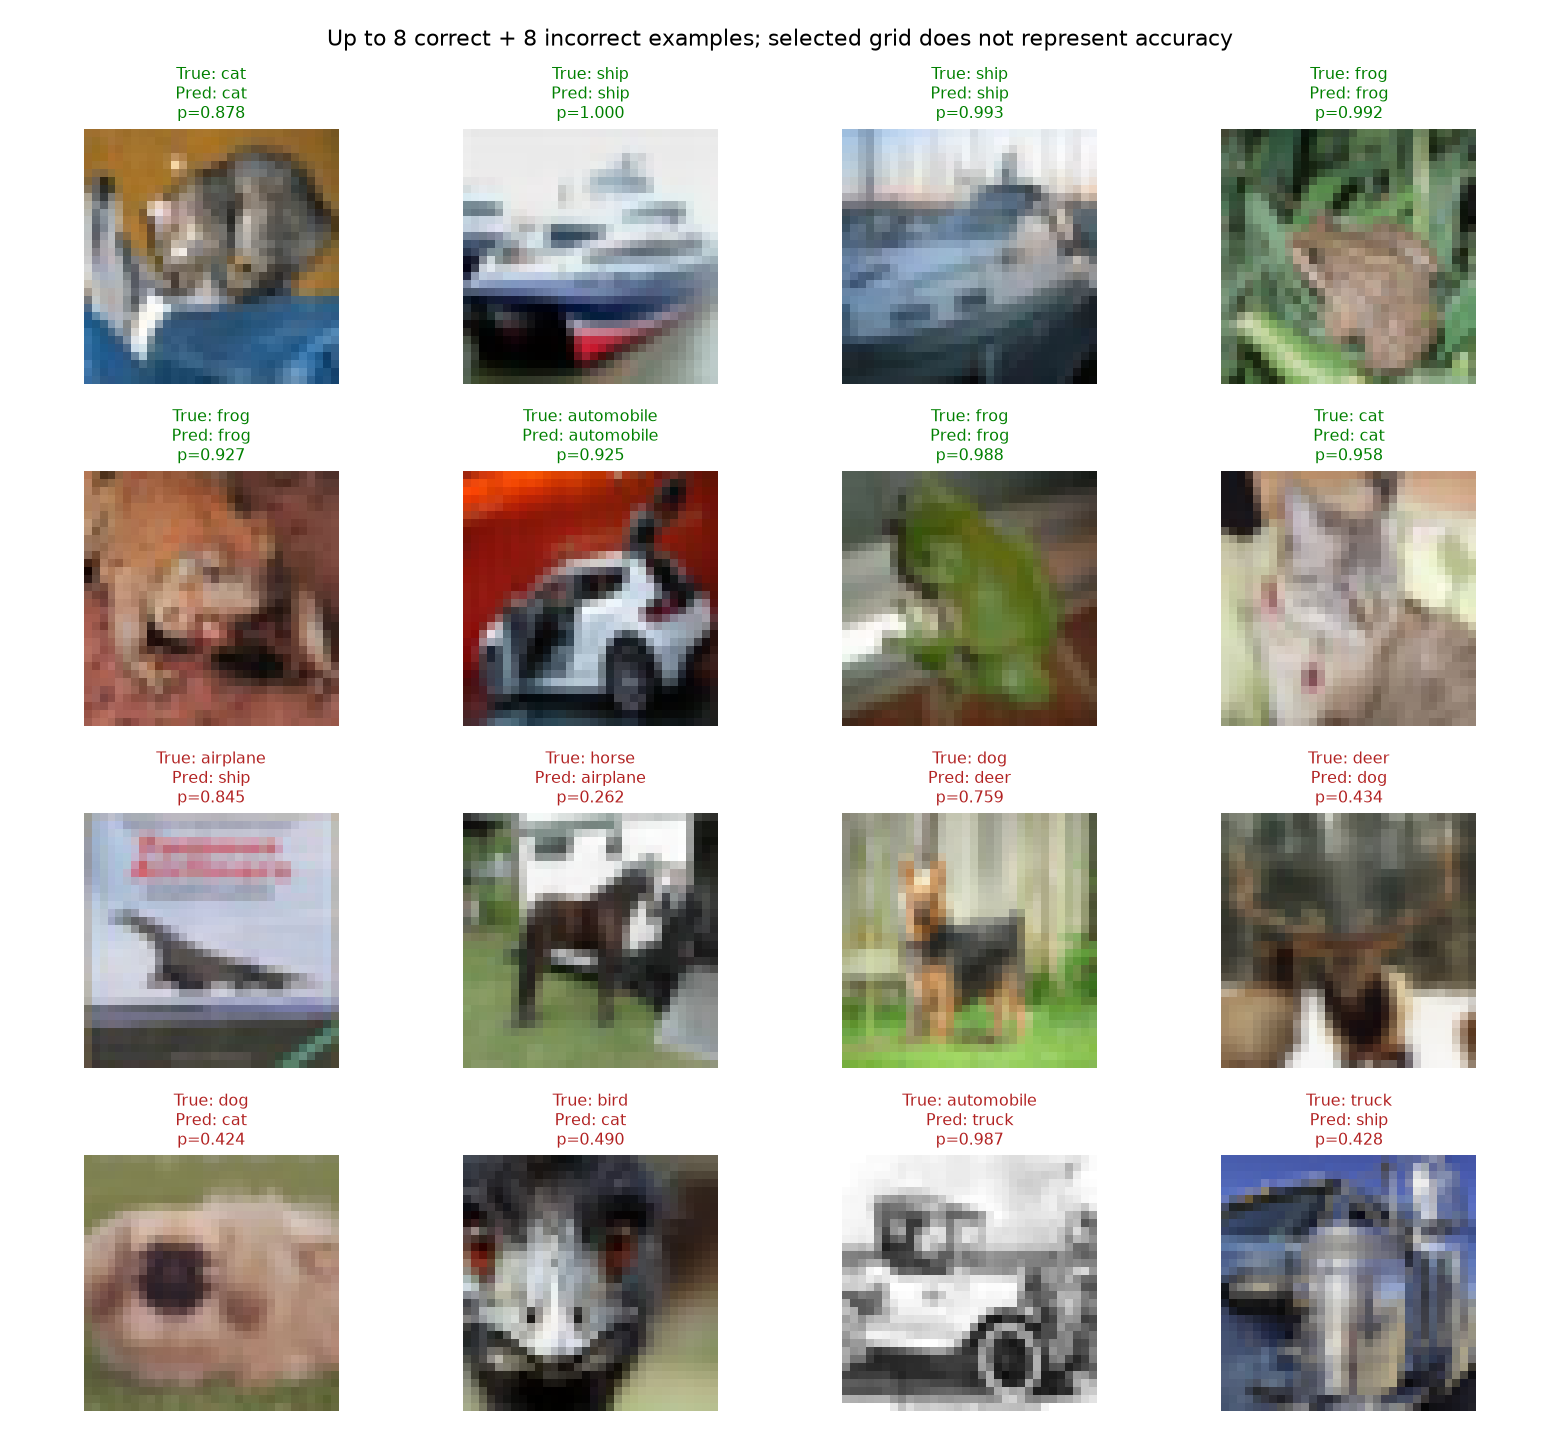

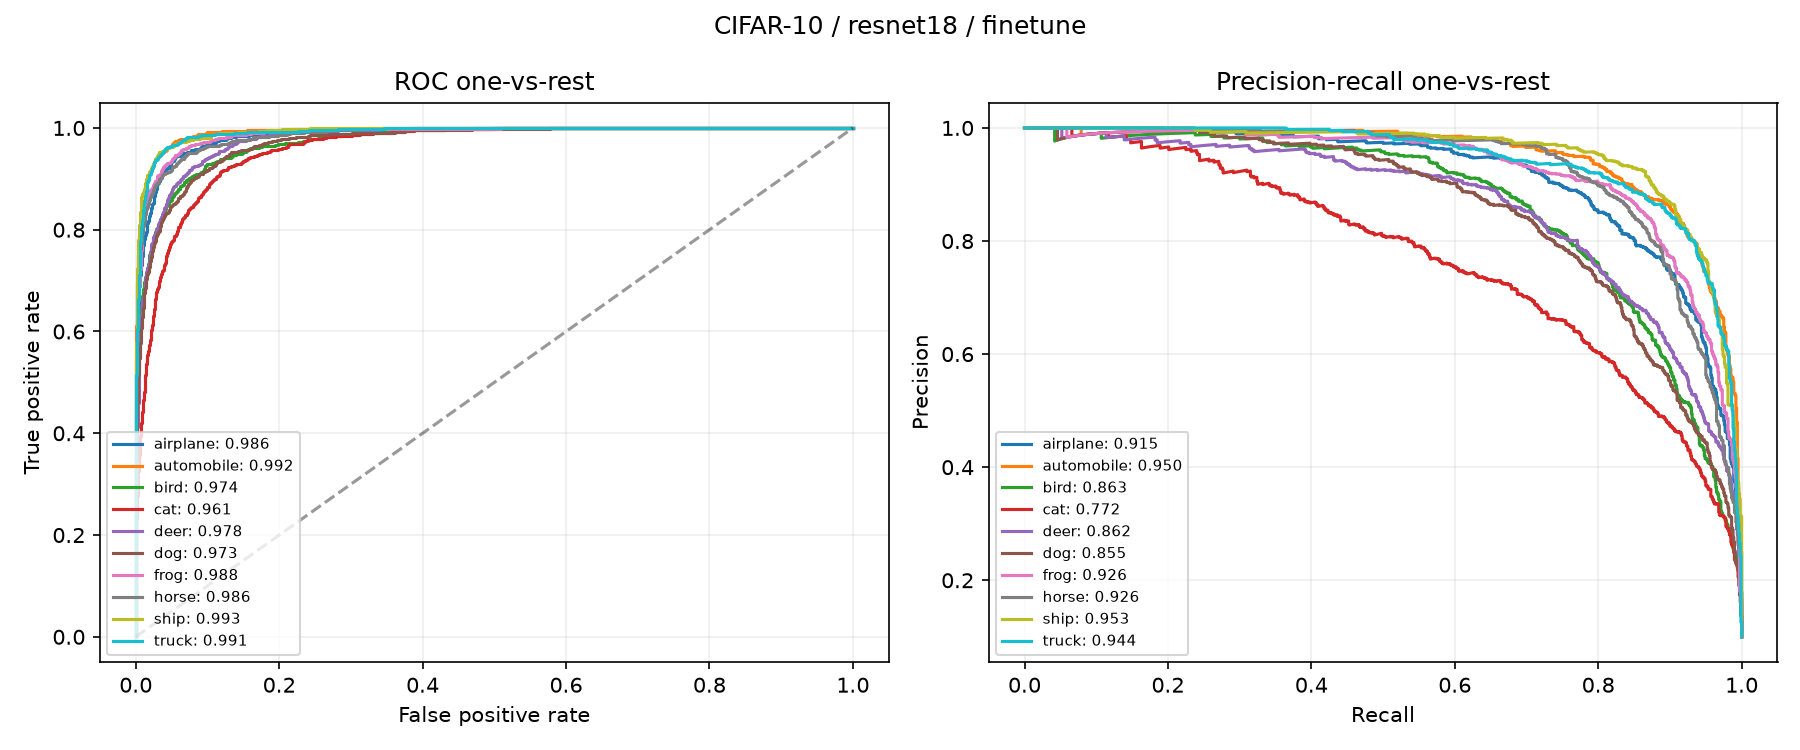

densenet121 head_selected


,precision,recall,f1-score,support
airplane,0.785305,0.8230,0.803711,1000.0000
automobile,0.845084,0.8510,0.848032,1000.0000
bird,0.769657,0.6950,0.730426,1000.0000
cat,0.621025,0.7030,0.659475,1000.0000
deer,0.773303,0.6720,0.719101,1000.0000
dog,0.826923,0.6450,0.724719,1000.0000
frog,0.790353,0.8520,0.820019,1000.0000
horse,0.741882,0.8910,0.809632,1000.0000
ship,0.831749,0.8750,0.852827,1000.0000
truck,0.875269,0.8140,0.843523,1000.0000


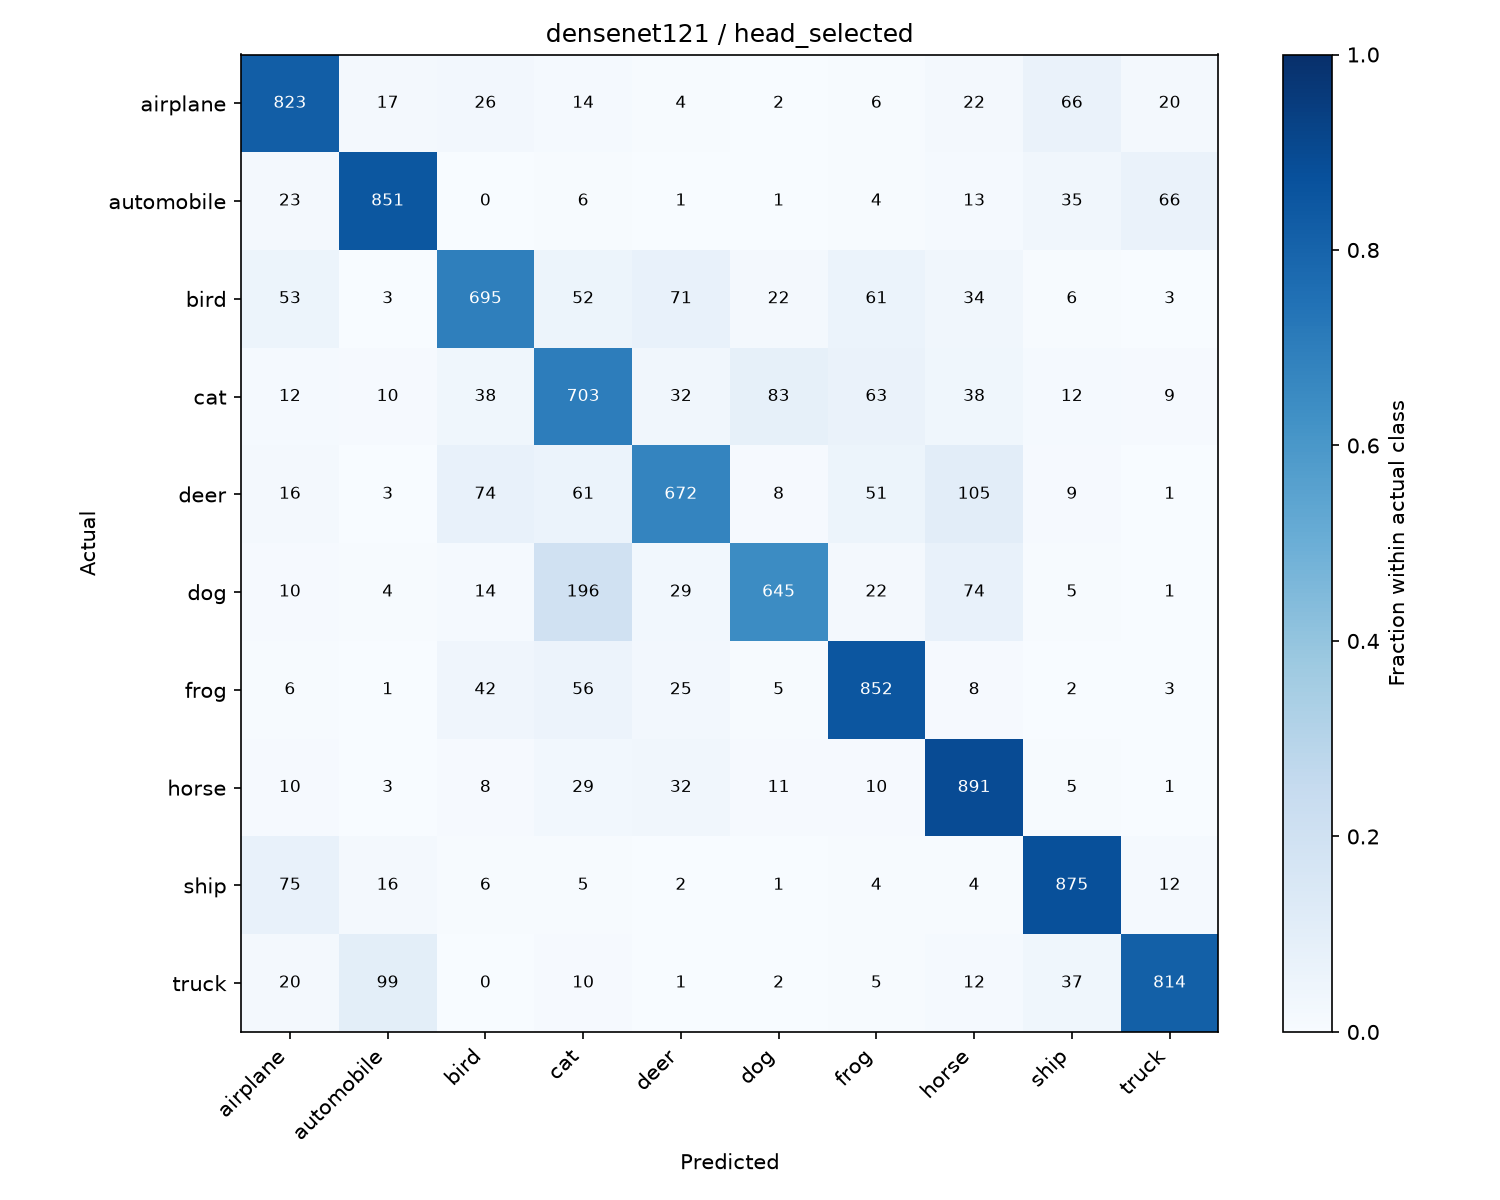

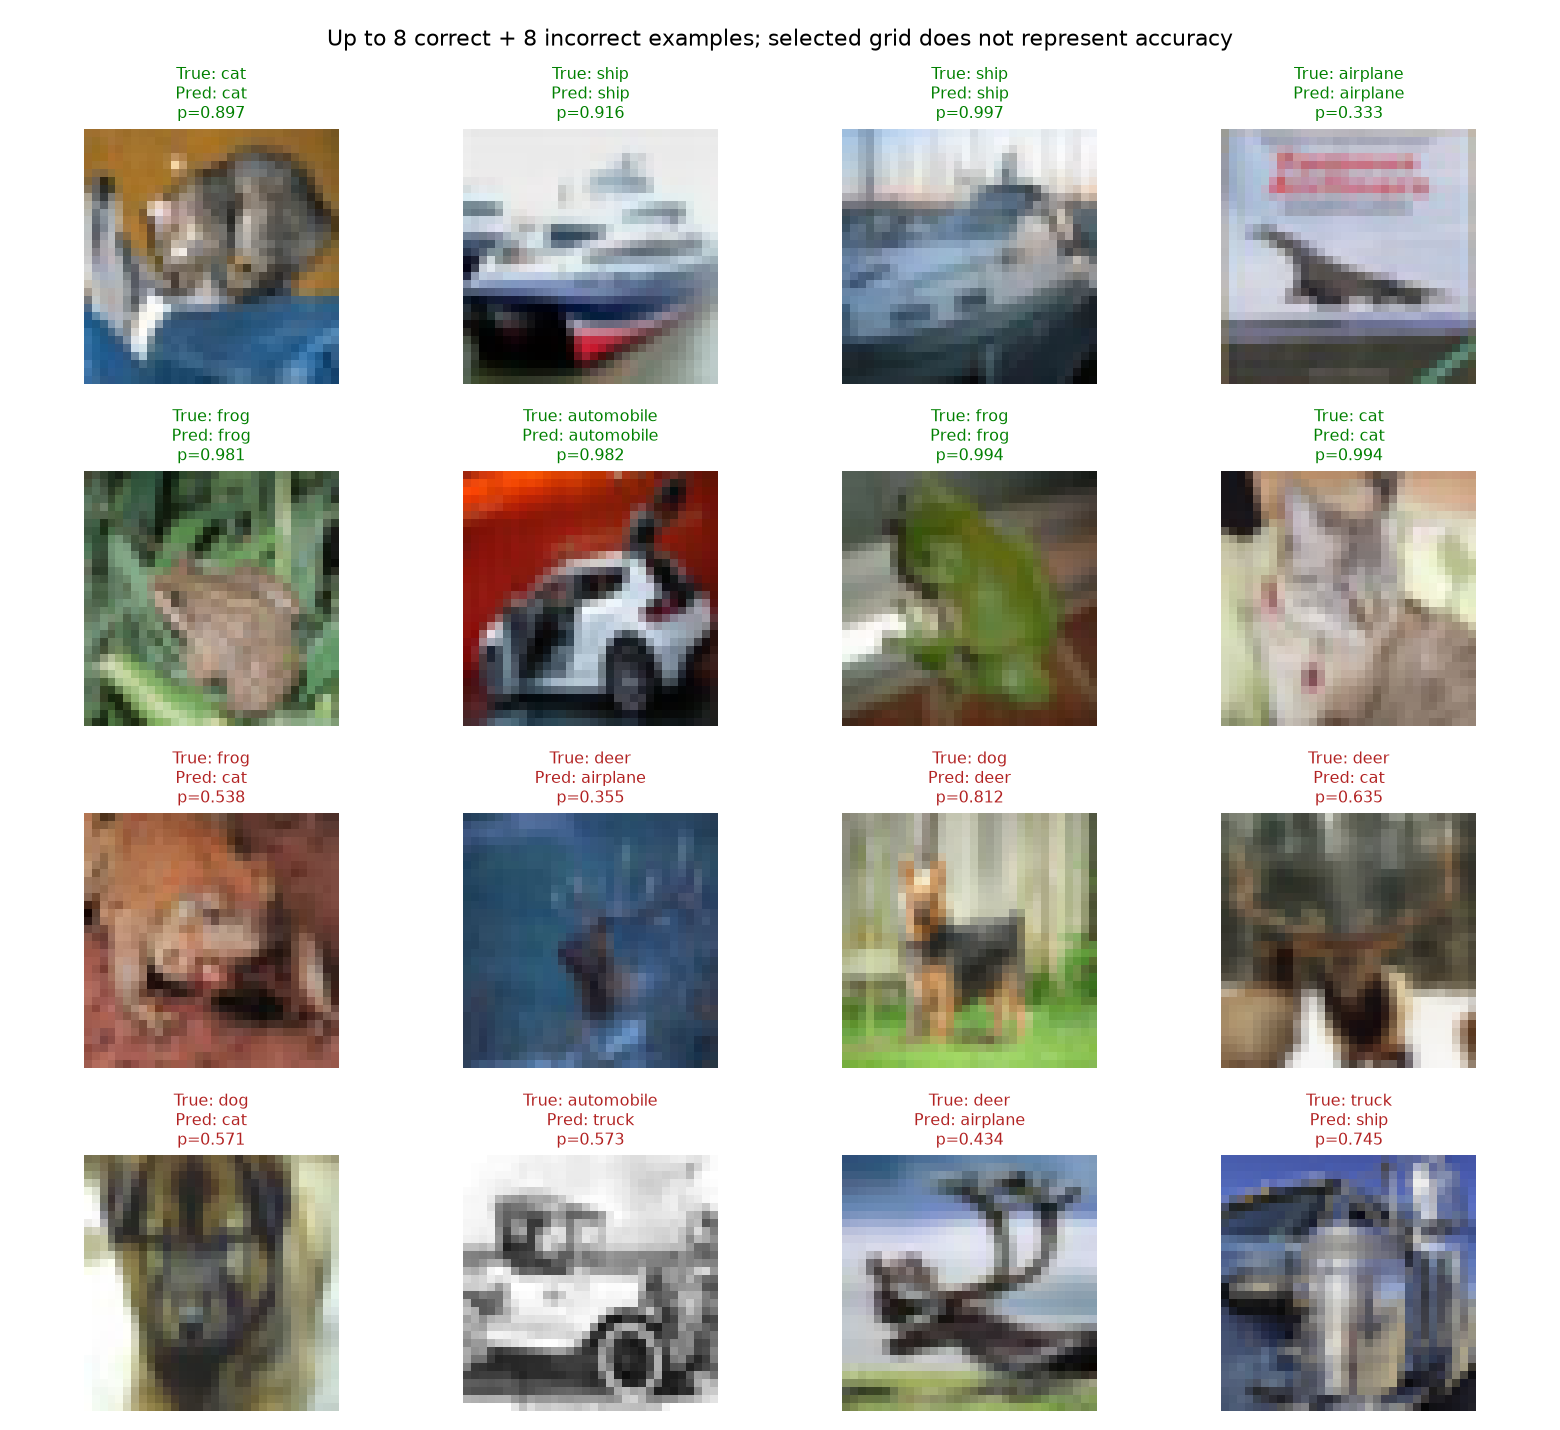

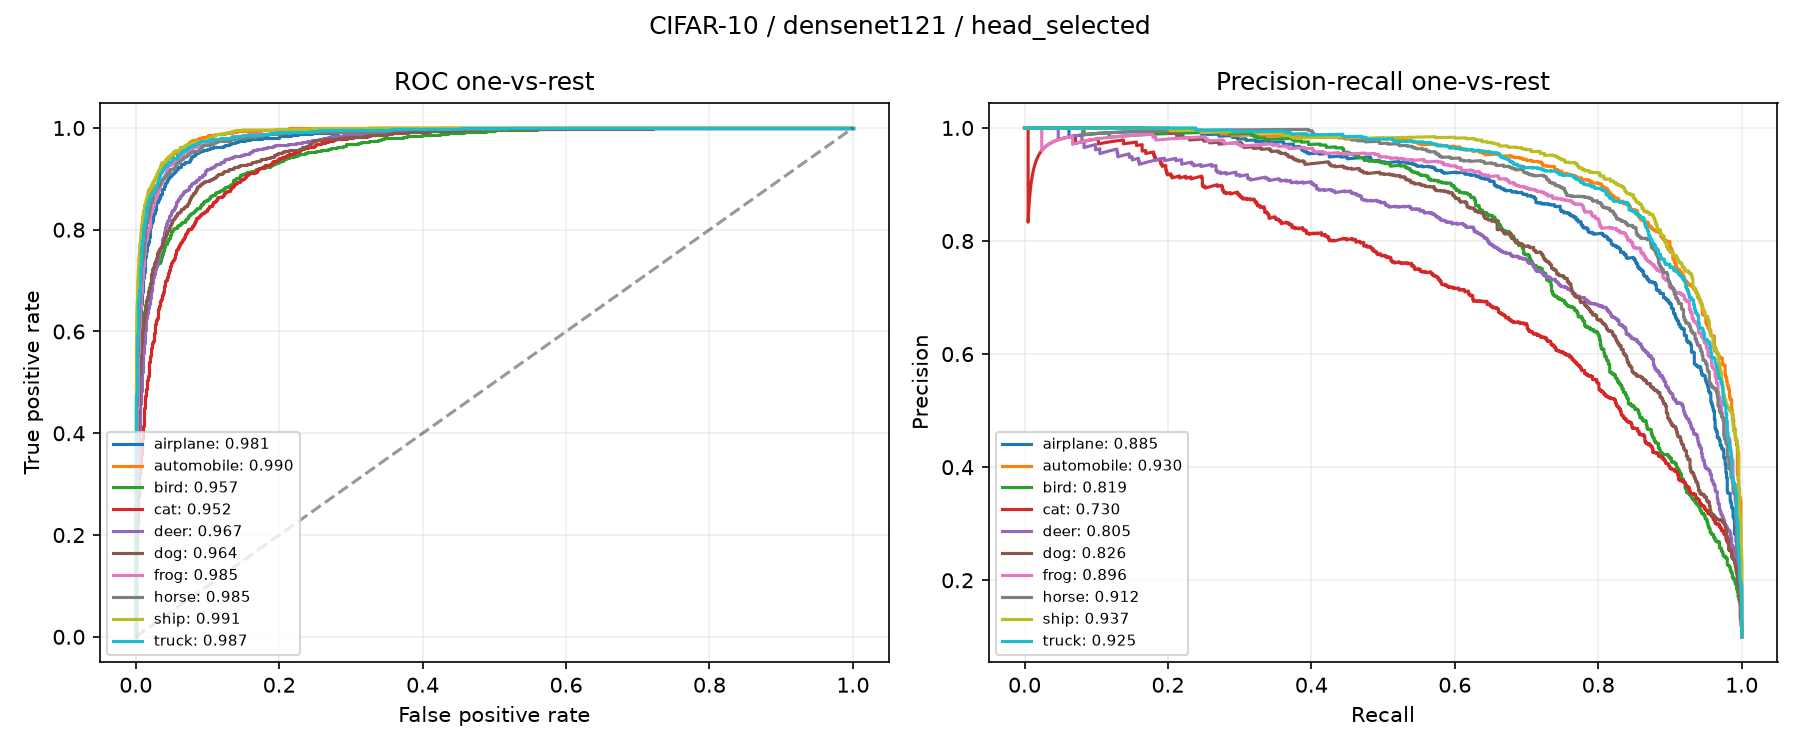

densenet121 finetune


,precision,recall,f1-score,support
airplane,0.842105,0.8320,0.837022,1000.0000
automobile,0.876531,0.8590,0.867677,1000.0000
bird,0.778807,0.7570,0.767748,1000.0000
cat,0.682617,0.6990,0.690711,1000.0000
deer,0.781947,0.7710,0.776435,1000.0000
dog,0.784744,0.7510,0.767501,1000.0000
frog,0.833494,0.8660,0.849436,1000.0000
horse,0.854437,0.8570,0.855716,1000.0000
ship,0.865234,0.8860,0.875494,1000.0000
truck,0.851996,0.8750,0.863345,1000.0000


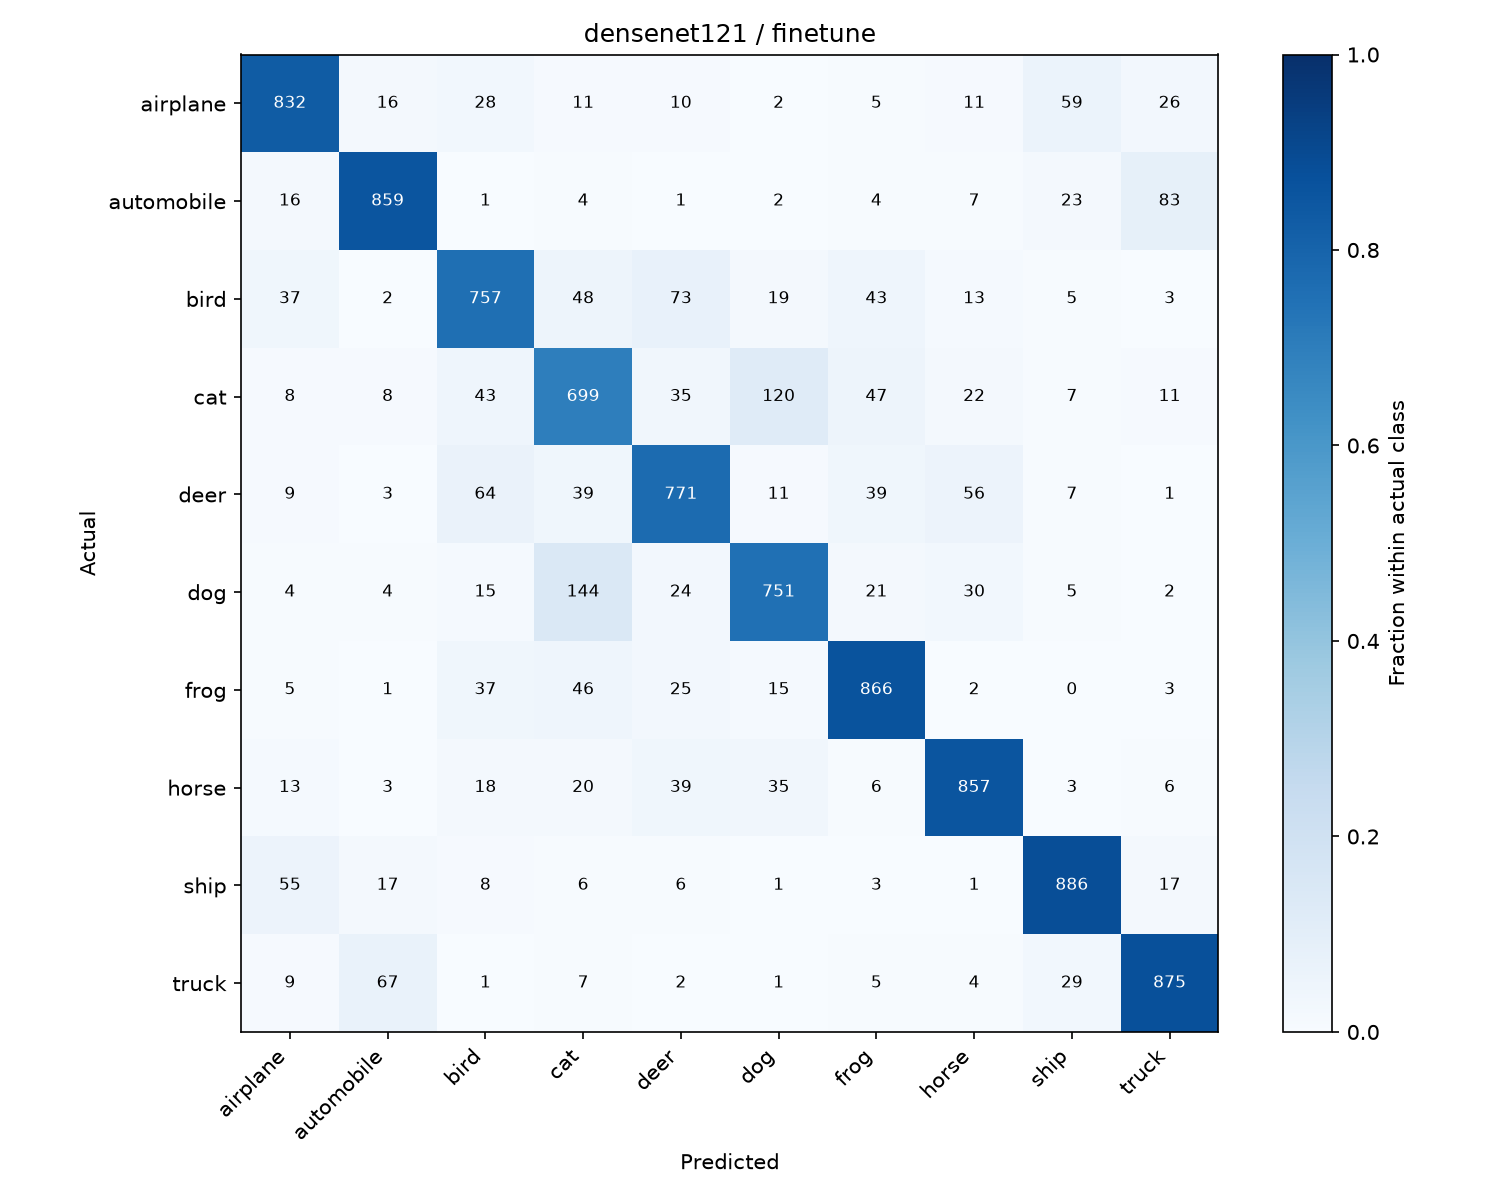

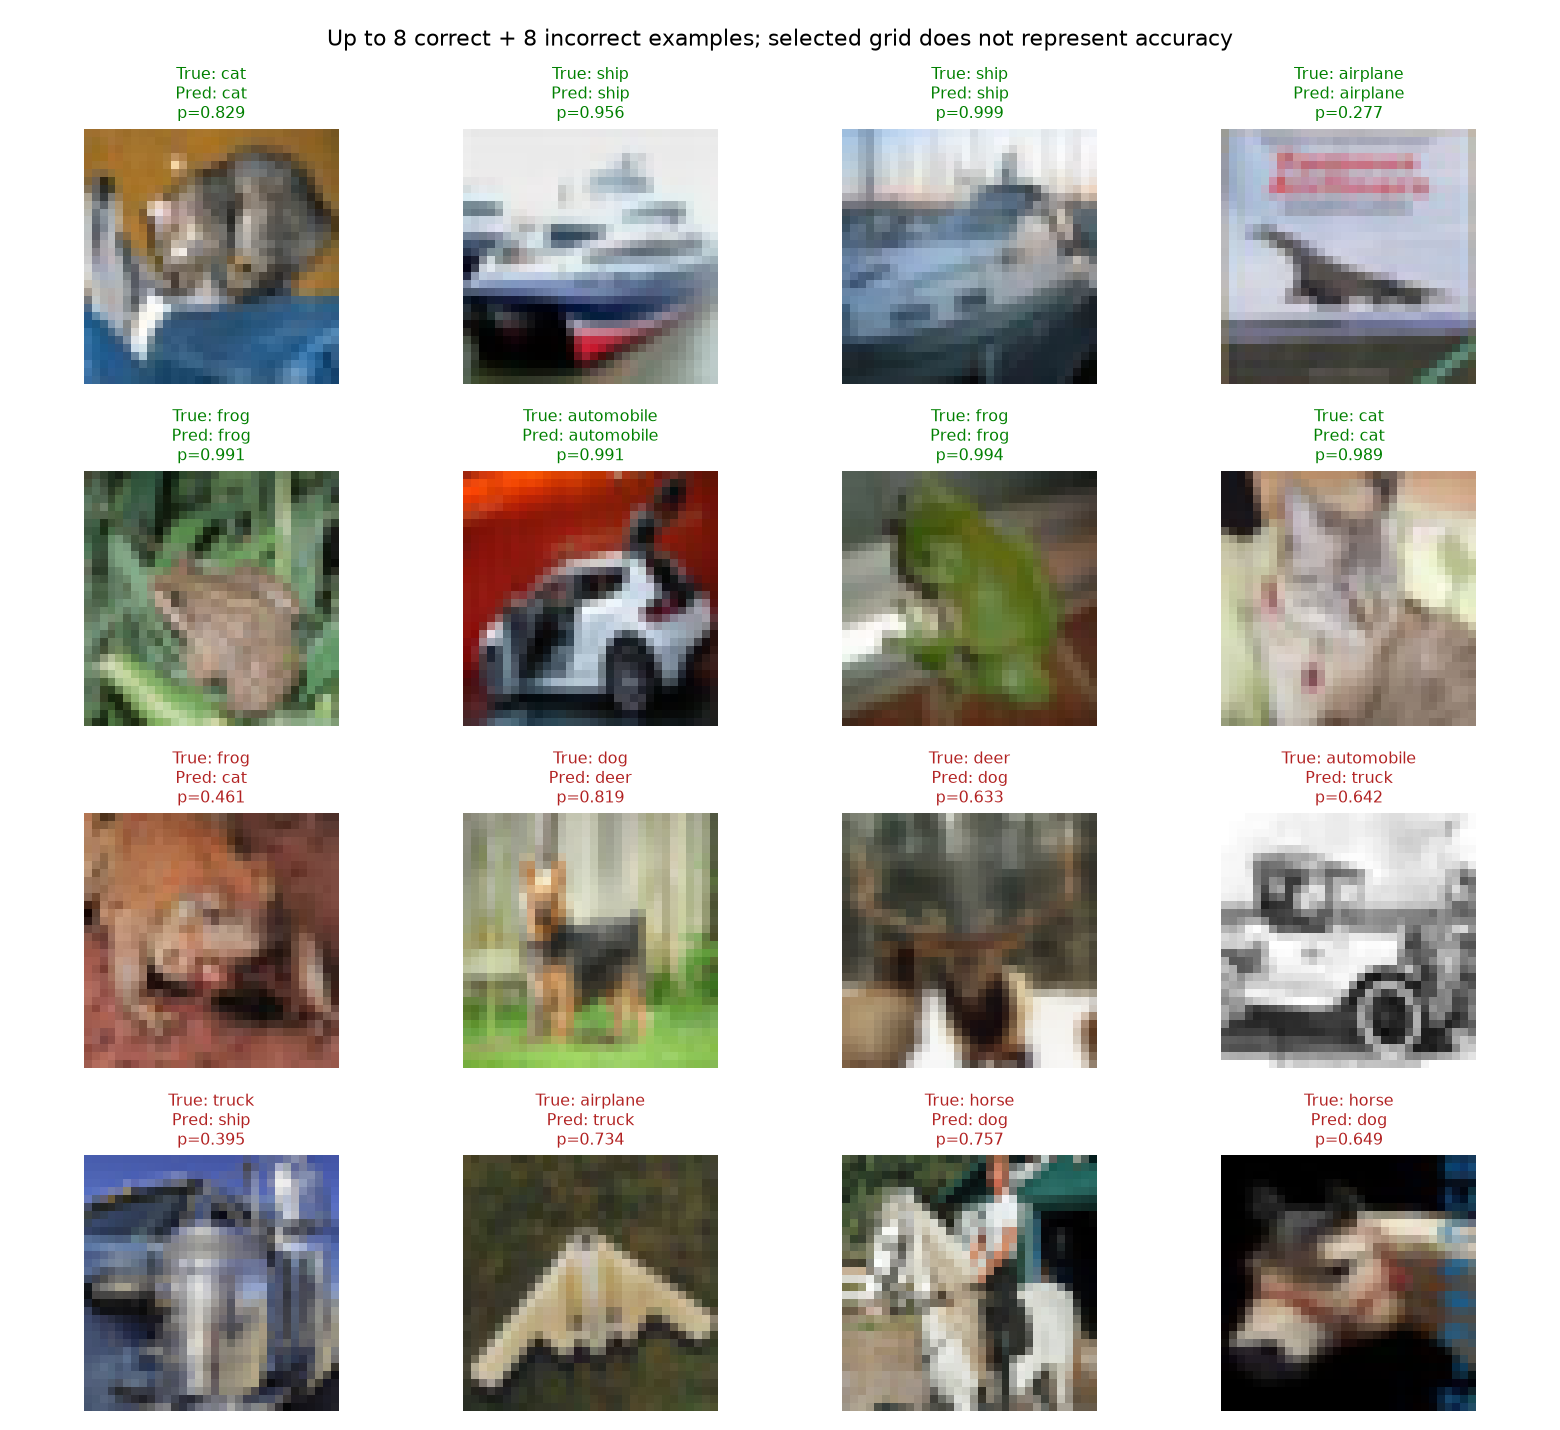

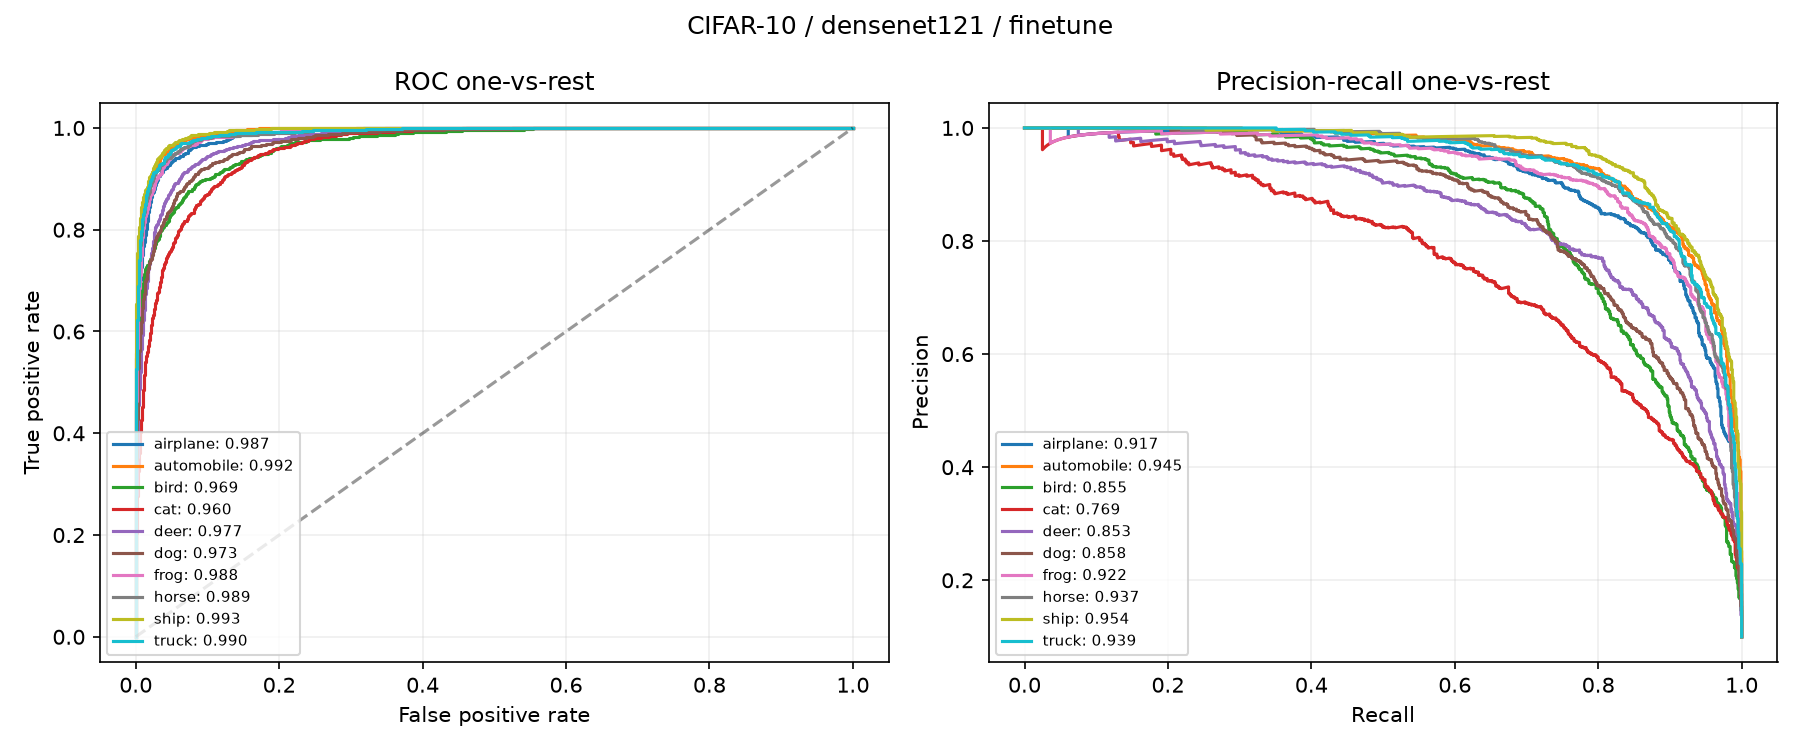

In [7]:
for name in run_cfg['models']:
    for stage in ['head_selected', 'finetune']:
        folder = RUN / name / stage
        print(name, stage)
        display(pd.read_csv(folder / 'classification_report.csv', index_col=0))
        display(Image(filename=str(folder / 'confusion_matrix.png')))
        display(Image(filename=str(folder / 'prediction_examples.png')))
        if (folder / 'roc_pr.png').exists():
            display(Image(filename=str(folder / 'roc_pr.png')))


## 8. Save / Load model

Mỗi condition đã được load vào instance mới trước khi đánh giá test. Checkpoint chứa state_dict và metadata kiến trúc. Phép roundtrip so xác suất của hai instance trên cùng ảnh ở eval mode. Cell sau minh họa tải model đã chọn để dùng lại, không tải weights ImageNet lần nữa.


In [8]:
import torch
name = run_cfg['models'][0]
saved = torch.load(RUN / name / 'finetune' / 'best.pt', map_location='cpu', weights_only=True)
LOADED_MODEL = build_model(name, pretrained=False)
LOADED_MODEL.load_state_dict(saved['state_dict'])
LOADED_MODEL.eval()
for model_name in run_cfg['models']:
    for stage in ['head_selected', 'finetune']:
        check = json.loads((RUN / model_name / stage / 'roundtrip.json').read_text(encoding='utf-8'))
        assert check['passed'], check
        print(model_name, stage, check)
print('LOADED_MODEL:', name)


resnet18 head_selected {'samples': 8, 'max_probability_error': 0.0, 'passed': True}
resnet18 finetune {'samples': 8, 'max_probability_error': 0.0, 'passed': True}
densenet121 head_selected {'samples': 8, 'max_probability_error': 0.0, 'passed': True}
densenet121 finetune {'samples': 8, 'max_probability_error': 0.0, 'passed': True}
LOADED_MODEL: resnet18


## 9. Kết luận và bằng chứng

In [9]:
text = (RUN / 'report_vi.md').read_text(encoding='utf-8')
# Figures are displayed above with resolved paths; keep report text portable here.
text = '\n'.join(line for line in text.splitlines() if not line.startswith('!['))
display(Markdown(text))
manifest = json.loads((RUN / 'manifest.json').read_text(encoding='utf-8'))
print('Files recorded in manifest:', len(manifest))


# Lab 02 — Transfer Learning trên CIFAR10

## 1. Mục tiêu
Khảo sát ResNet18 và DenseNet121 pre-trained ImageNet, thay classifier thành 10 lớp, so sánh đóng băng backbone và fine-tune block cuối. Điều chỉnh learning rate/batch size, theo dõi bằng TensorBoard, đánh giá và lưu/tải model.

## 2. Dữ liệu và phạm vi thực nghiệm
Toàn bộ split CIFAR-10; ngân sách epoch và độ phân giải được ghi rõ bên dưới.
Profile: `cifar10_cpu_full64`. Train/validation/test thực tế: 45,000/5,000/10,000. Seed: 42.
Split gốc 45.000/5.000 được tạo stratified; test giữ nguồn test chính thức. Khi chạy pilot, mỗi split được lấy tập con stratified riêng. Mỗi lớp có 4.500 train / 500 validation / 1.000 test khi dùng toàn bộ dữ liệu.
Ảnh RGB gốc 32×32 được giữ màu. Đầu vào thực nghiệm là 64×64; normalization dùng mean/std của weights IMAGENET1K_V1. Với 224×224, dùng trọn transforms chính thức; với 64×64, resize trực tiếp để phù hợp ngân sách CPU, không phải preprocessing mặc định của weights. Không augmentation trong thí nghiệm này để tái sử dụng feature đóng băng và giữ tiền xử lý nhất quán.

## 3. Phương pháp
Mỗi mô hình thay classifier bằng Linear 10 đầu ra. Head-only đóng băng backbone và cache feature train/val ở eval mode. Cache tương đương forward backbone cho đầu vào cố định; thời gian trích xuất được ghi riêng.
Tìm learning rate [0.001, 0.01] và batch size [32, 64], 5 epoch/candidate với AdamW, weight_decay=0.0001. Các candidate dùng cùng initial head và shuffle seed. Chọn bằng best validation accuracy; hòa chọn trial sớm nhất.
Fine-tune bắt đầu từ head đã chọn; mở layer4 của ResNet18 hoặc denseblock4+norm5 của DenseNet121. Backbone LR=1e-05, head LR=0.0001, 2 epoch. BatchNorm giữ running statistics; các affine weights trong block được mở vẫn có gradient.
CrossEntropyLoss nhận logits. Checkpoint chọn theo validation. Test không tham gia search hoặc lựa chọn checkpoint; hai điều kiện head/fine-tune được xác định trước và đánh giá sau khi khóa lựa chọn. Mỗi condition được tải vào model instance mới trước đánh giá.

## 4. Kết quả đo được
| Model | Stage | Val acc | Test acc | Macro F1 | Trainable | Train (s) |
|---|---|---:|---:|---:|---:|---:|
| resnet18 | head | 77.16% | 76.09% | 0.7611 | 5,130 | 8.9 |
| resnet18 | finetune | 82.10% | 81.49% | 0.8146 | 8,398,858 | 1084.7 |
| densenet121 | head | 79.24% | 78.21% | 0.7811 | 10,250 | 9.0 |
| densenet121 | finetune | 81.46% | 81.53% | 0.8151 | 2,170,378 | 219.7 |

- resnet18: fine-tune thay đổi test accuracy +5.40 điểm phần trăm và Macro F1 +0.0536 so với head-only.
- densenet121: fine-tune thay đổi test accuracy +3.32 điểm phần trăm và Macro F1 +0.0340 so với head-only.


Train (s) chỉ là thời gian fit candidate được chọn hoặc fine-tune, chưa bao gồm feature extraction/search. `training_summary.json` của head_selected ghi riêng thời gian trích xuất và tổng search. Vì fine-tune tiếp tục từ head, chi phí toàn pipeline phải cộng các giai đoạn.

## 5. Phân tích và giới hạn
Kết quả chỉ đại diện cho seed và phạm vi dữ liệu đã ghi. Fine-tune có thêm epoch và được khởi tạo từ head đã học; chênh lệch phản ánh chiến lược hai giai đoạn, chưa cô lập tác động unfreeze ở cùng ngân sách tính toán.
Không mặc định pre-trained hoặc fine-tune phải tốt hơn. Tập nguồn ImageNet khác phân phối ảnh CIFAR-10 độ phân giải thấp. Phóng ảnh không bổ sung thông tin chi tiết mới.
Không so sánh trực tiếp với Lab1 vì FashionMNIST và CIFAR-10 là hai bài toán khác nhau. Cấu hình CPU 64×64 và GPU 224×224 cũng phải được báo cáo riêng; không suy diễn kết quả của cấu hình chưa chạy.

## 6. Bằng chứng và tái lập
`config.json`, `environment.json`, `source_hashes.json`, hai NPZ indices, `console.log`, `status.json` và SHA256 manifest ghi điều kiện chạy. Từng kiến trúc có architecture, parameters, preprocessing, search_results, selection, TensorBoard event và learning curves. Mỗi condition có best.pt, history, classification report, confusion counts, probabilities, ảnh đúng/sai và roundtrip.json.
Lưới ảnh chọn tối đa 8 đúng/8 sai để minh họa; xác suất softmax không bảo đảm dự đoán đúng. Số trong confusion matrix là count, màu chuẩn hóa theo lớp thật.

## 7. Tài liệu tham khảo
- [Torchvision models và weights](https://docs.pytorch.org/vision/main/models)
- [PyTorch transfer learning](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial)
- [TensorBoard với PyTorch](https://docs.pytorch.org/tutorials/intermediate/tensorboard_tutorial)

## 8. Khảo sát lỗi và hình bổ sung

### Dữ liệu RGB và phân bố lớp


| Class | Train | Validation | Test |
|---|---:|---:|---:|
| airplane | 4500 | 500 | 1000 |
| automobile | 4500 | 500 | 1000 |
| bird | 4500 | 500 | 1000 |
| cat | 4500 | 500 | 1000 |
| deer | 4500 | 500 | 1000 |
| dog | 4500 | 500 | 1000 |
| frog | 4500 | 500 | 1000 |
| horse | 4500 | 500 | 1000 |
| ship | 4500 | 500 | 1000 |
| truck | 4500 | 500 | 1000 |

- resnet18/head_selected: cặp lỗi nhiều nhất dog → cat (147 ảnh trong tập test đã chọn).

**Ba lớp F1 thấp nhất — resnet18/head_selected:**

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| cat | 0.6340 | 0.6460 | 0.6399 |
| bird | 0.7283 | 0.6700 | 0.6979 |
| deer | 0.6712 | 0.7410 | 0.7044 |

- resnet18/finetune: cặp lỗi nhiều nhất dog → cat (145 ảnh trong tập test đã chọn).

**Ba lớp F1 thấp nhất — resnet18/finetune:**

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| cat | 0.6948 | 0.6990 | 0.6969 |
| dog | 0.7878 | 0.7350 | 0.7605 |
| bird | 0.7578 | 0.7760 | 0.7668 |


### resnet18






- densenet121/head_selected: cặp lỗi nhiều nhất dog → cat (196 ảnh trong tập test đã chọn).

**Ba lớp F1 thấp nhất — densenet121/head_selected:**

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| cat | 0.6210 | 0.7030 | 0.6595 |
| deer | 0.7733 | 0.6720 | 0.7191 |
| dog | 0.8269 | 0.6450 | 0.7247 |

- densenet121/finetune: cặp lỗi nhiều nhất dog → cat (144 ảnh trong tập test đã chọn).

**Ba lớp F1 thấp nhất — densenet121/finetune:**

| Class | Precision | Recall | F1 |
|---|---:|---:|---:|
| cat | 0.6826 | 0.6990 | 0.6907 |
| dog | 0.7847 | 0.7510 | 0.7675 |
| bird | 0.7788 | 0.7570 | 0.7677 |


### densenet121






### TensorBoard và chi phí


Hình này dựng từ TensorBoard events thật; không phải ảnh chụp giao diện. Mở TensorBoard theo README để xem tương tác.

Điều kiện được đề xuất bằng validation: **resnet18/finetune**, validation accuracy **82.10%**.

Chi phí pipeline gồm feature extraction, toàn bộ head search và fine-tune nếu có; chưa gồm EDA, ghi báo cáo và inference test. Xem cost_comparison.csv.

| Model | Stage | Feature extraction (s) | All head search (s) | Pipeline train (s) | Test (s) |
|---|---|---:|---:|---:|---:|
| resnet18 | head | 281.9 | 47.6 | 329.4 | 64.0 |
| resnet18 | finetune | 281.9 | 47.6 | 1414.1 | 62.8 |
| densenet121 | head | 478.1 | 43.4 | 521.5 | 100.4 |
| densenet121 | finetune | 478.1 | 43.4 | 741.2 | 92.4 |

### Cấu hình head được chọn bằng validation

| Model | LR | Batch | Best epoch | Validation accuracy |
|---|---:|---:|---:|---:|
| resnet18 | 0.001 | 64 | 5 | 77.16% |
| densenet121 | 0.001 | 64 | 5 | 79.24% |

densenet121 fine-tune sử dụng cache đầu ra của prefix đóng băng; đã kiểm chứng tương đương trên 8 ảnh thật, max logit error=0. Test vẫn forward toàn bộ model trên ảnh RGB. Kiểm thử riêng đối chiếu cả logits, gradients và schema checkpoint.

Chi phí giữa các kiến trúc chịu ảnh hưởng của cách thực thi: xem cột execution trong cost_comparison.csv. Trong run này, nếu một model dùng cache prefix còn model khác forward ảnh khi fine-tune, không dùng thời gian thô để kết luận riêng về tốc độ kiến trúc. Cache giữ nguyên bài toán tối ưu và số ảnh/epoch; mã hiện hành hỗ trợ cache prefix cho cả hai model ở profile CPU.

### Diễn giải chỉ số và thiết kế

Accuracy là số ảnh dự đoán đúng chia tổng số ảnh. Macro F1 tính F1 riêng cho từng lớp rồi lấy trung bình không trọng số; vì vậy mỗi lớp đóng góp ngang nhau. Macro Precision/Recall và cross-entropy test được lưu trong metrics.json. ROC-AUC và average precision tính one-vs-rest từng lớp, không phải cùng một đại lượng.

ResNet dùng residual connections để cộng tín hiệu qua các block; DenseNet nối các feature maps từ nhiều lớp trong dense block. Thực nghiệm thay head và giữ cấu trúc backbone gốc, không thiết kế lại CNN từ đầu.

CPU profile chỉ có 2 epoch fine-tune sau head search: kết quả chứng minh pipeline và hành vi ở ngân sách đã chọn, không chứng minh đã hội tụ hoặc đạt chất lượng tối ưu. Chưa chạy nhiều seed, augmentation ablation hay baseline khởi tạo ngẫu nhiên.

Files recorded in manifest: 211
